# 사출성형 공정데이터 기반 품질불량 위험 예측 및 검사 우선순위 결정

사출이 끝난 뒤 기록된 공정값(사이클 시간, 충전 시간, 최대 사출압, 쿠션 위치 등)으로 품질검사 전에 제품별 위험점수를 매겨
검사 순서와 검사 대상을 정한다. 사출 전에 불량을 막는 예측이 아니며, 기존 품질검사를 대체하지 않고 한정된 검사 용량을
어디에 먼저 쓸지 정하는 검사 보조 도구를 목표로 한다.

| 평가 항목 (배점) | 위치 | 주요 내용 |
|---|---|---|
| 데이터 이해 및 진단 (15) | 1장 | 데이터 정의, 추정 사출 그룹 구조, 라벨 충돌, 품질 요약, 예측 시점 |
| AI 예측모델 개발 (40) | 2장 | 검증 3종, 분할 누수 점검, 사전 규칙에 따른 선정, 유의성·다중비교, 판정 관점 분리 |
| 영향요인 및 오류분석 (15) | 3장 | SHAP 예측 기여 변수, 제품별 기여 방향, 운영점 FN·FP 집중 조건 |
| 현장 활용방안 (10) | 4장 | 검사 용량별 포착표, 규칙 베이스라인, 비용 시나리오, 등급별 조치, 모니터링 |
| 창의성·차별성 (10) | 5장 | 차별 요소 요약 |
| 코드 및 재현성 (10) | 0장, 6장 | 실행 기록, 강제 재실행, 저장 모델·추론 스크립트, 결과 일치 확인 |

용어
- 추정 사출 그룹: 공정값이 같은 행 묶음 (설비 사출 번호가 아님)
- 추정 캐비티: 그룹 안의 행 순서 (설비 캐비티 번호가 아님)
- 위험점수: 보정 전 모델 출력. 순위에만 쓰고 확률로 읽지 않는다.
- 보정 확률: 사출 그룹 단위 내부 CV 로 보정한 확률 추정치
- 예측 기여 변수: 모델 점수를 올린 변수 (SHAP). 불량 원인을 뜻하지 않는다.

분석 로직은 `src/` 에 있고, 이 노트북은 `run_all.py` 가 저장한 결과를 읽어 시각화한다.

In [ ]:
!pip install --user -r requirements.txt

## 0. 환경 설정 · 실행 제어

In [2]:
import json
import warnings
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
import matplotlib.font_manager as fm

from src import insights as ins
from src.config import INDEX_COL, OUT_DIR, SEED, TARGET
from src.data import diagnose, feature_columns, feature_matrix, load_all, load_labeled, process_cols, scaling_check
from src.evaluate import best_threshold, inner_oof, metrics
from src.models import get_models
from run_all import holdout_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
sns.set_style("whitegrid")
_installed = {f.name for f in fm.fontManager.ttflist}
KOREAN_FONT = next((f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR"]
                    if f in _installed), None)
plt.rcParams["font.family"] = [KOREAN_FONT, "DejaVu Sans"] if KOREAN_FONT else ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 축 눈금의 음수 기호 깨짐 방지
print("그래프 폰트:", plt.rcParams["font.family"])

그래프 폰트: ['Malgun Gothic', 'DejaVu Sans']


In [3]:
# 핵심 결과가 없거나 FORCE_RERUN=True 면 파이프라인을 실행한다 (CPU 약 1시간).
# 부가 실험 결과가 없으면 해당 셀만 건너뛴다.
FORCE_RERUN = False

import run_all
from src.config import CORE_OUTPUTS, EXTRA_OUTPUTS

missing_core = [f for f in CORE_OUTPUTS if not (OUT_DIR / f).exists()]
if FORCE_RERUN or missing_core:
    print("파이프라인 실행, 누락된 핵심 결과:", missing_core[:5])
    run_all.main()

MANIFEST = json.loads((OUT_DIR / "run_manifest.json").read_text(encoding="utf-8"))
changed = [k for k, v in run_all.file_hashes().items() if MANIFEST["input_hashes"].get(k) != v]
print(f"결과 폴더: {OUT_DIR.name} | 모드: {MANIFEST['mode']} | 상태: {MANIFEST['status']} | "
      f"완료: {MANIFEST['finished']} | 소요 {MANIFEST['runtime_sec'] / 60:.0f}분 | 부가 실험: {MANIFEST['run_extra']}")
if MANIFEST["mode"] != "full":
    print("주의: --quick 결과입니다 (반복 1회).")
if changed:
    print("주의: 결과 생성 이후 바뀐 파일:", changed, "(FORCE_RERUN=True 로 다시 실행)")

EXTRA = {f: (OUT_DIR / f).exists() for f in EXTRA_OUTPUTS}


def has_extra(f):
    if not EXTRA.get(f, False):
        print(f"[건너뜀] {f} 없음 (부가 실험 미실행)")
    return EXTRA.get(f, False)


def na(df, digits=3):
    """분모가 0 이라 정의되지 않는 값은 N/A 로 표시."""
    return df.round(digits).astype(object).where(df.notna(), "N/A")


import re
from IPython.display import Markdown as _Markdown


def Markdown(text):
    """줄 앞 들여쓰기 제거 (if 블록 안에서도 마크다운으로 표시)."""
    return _Markdown(re.sub(r"(?m)^[ \t]+", "", text))

결과 폴더: outputs | 모드: full | 상태: done | 완료: 2026-10-05T22:27:14 | 소요 59분 | 부가 실험: True


### 핵심 결과 요약
아래 수치는 `outputs/` 의 결과 파일에서 읽는다. 자세한 근거는 각 장에 있다.

In [4]:
diag0 = pd.read_csv(OUT_DIR / "data_diagnosis.csv").set_index("product")
st0 = pd.read_csv(OUT_DIR / "structure_summary.csv").set_index("product")
cv0 = pd.read_csv(OUT_DIR / "cv_folds.csv")
tm0 = json.loads((OUT_DIR / "test_metrics.json").read_text(encoding="utf-8"))
ci0 = pd.read_csv(OUT_DIR / "test_bootstrap_ci.csv").set_index(["scope", "metric"]).loc[("all", "PR_AUC")]
cap0 = pd.read_csv(OUT_DIR / "capacity_table.csv").set_index(["정책", "검사 용량", "scope"])
fwd0 = pd.read_csv(OUT_DIR / "forward_cv.csv")
cal0 = pd.read_csv(OUT_DIR / "calibration_oof.csv")

m0, f0 = tm0["model"], tm0["features"]
n_rows, n_fail = int(diag0.rows.sum()), int(diag0.fail_rows.sum())
base0 = n_fail / n_rows
best0 = cv0[(cv0.scope == "all") & (cv0.model == m0) & (cv0.features == f0)][["PR_AUC", "Recall@20%"]].mean()
c20 = cap0.loc[("제품별 할당", 0.2, "all")]
p_cal = cal0[f"prob_{tm0['calibration']}"]
grade0 = pd.cut(p_cal, [-np.inf, tm0["grade_cut"]["주의"], tm0["grade_cut"]["위험"], np.inf], labels=["정상", "주의", "위험"], right=False)
gr0 = cal0.groupby(grade0, observed=True)[TARGET].mean()
cn7_na = int(((fwd0.features == f0) & (fwd0.scope == "cn7") & (fwd0["사유"].fillna("") != "")).sum())

rows0 = [
    ["데이터", f"라벨 {n_rows:,}행, 불량 {n_fail}건({base0 * 100:.1f}%), 추정 사출 그룹 {int(st0['[최종] 추정 사출 그룹 수'].sum()):,}개"],
    ["데이터 진단", f"불량 {int(diag0.fail_at_cavity0.sum())}건이 추정 캐비티 0, RG3 불량 {int(diag0.loc['rg3', 'fails_in_conflicting'])}/{int(diag0.loc['rg3', 'fail_rows'])}건이 같은 공정값의 양품과 충돌"],
    ["최종모델", f"{m0} / {f0} (사전 규칙: 개발셋 CV PR-AUC 최대). 상위권과의 차이는 통계적으로 유의하지 않음"],
    ["① 무작위 사출 그룹 CV", f"PR-AUC {best0.PR_AUC:.3f} (무작위 {base0:.3f}의 {best0.PR_AUC / base0:.1f}배), Recall@20% {best0['Recall@20%']:.3f} (fold 평균)"],
]
if EXTRA.get("time_block_cv.csv"):
    tb0 = pd.read_csv(OUT_DIR / "time_block_cv.csv")
    tb0 = tb0[(tb0.model == m0) & (tb0.features == f0)].groupby("n_blocks")["PR_AUC_all"].mean()
    rows0.append(["② 생산순번 블록 CV", f"PR-AUC {tb0.min():.3f}~{tb0.max():.3f} (같은 시기 사출을 학습에서 빼면 크게 낮아짐)"])
if EXTRA.get("leakage_cv.csv"):
    lk0 = pd.read_csv(OUT_DIR / "leakage_cv.csv").groupby(["model", "scheme"])["PR_AUC"].mean().unstack()
    rows0.append(["행 단위 검증과 비교", f"행 단위 CV 로 검증하면 {m0} PR-AUC 가 {(lk0.loc[m0, 'row'] / lk0.loc[m0, 'group'] - 1) * 100:+.0f}% 높게 나옴 (누수)"])
rows0 += [
    ["③ 과거→미래 대리 검증", f"CN7 은 평가 구간 {cn7_na}개 모두 불량 0건이라 평가 불가 (N/A), RG3 는 구간별 변동이 큼"],
    ["테스트셋 (불량 8건)", f"PR-AUC {tm0['all']['PR_AUC']:.3f} (95% CI {ci0.ci_low:.3f}~{ci0.ci_high:.3f}), CN7 {tm0['cn7']['PR_AUC']:.3f}, RG3 {tm0['rg3']['PR_AUC']:.3f}"],
    ["운영: 제품별 상위 20% 검사 (OOF 합산)", f"개발셋 불량 {int(c20['불량 수'])}건 중 {int(c20['포착 불량'])}건 포착 (CN7 {int(cap0.loc[('제품별 할당', 0.2, 'cn7'), '포착 불량'])}/{int(cap0.loc[('제품별 할당', 0.2, 'cn7'), '불량 수'])}, RG3 {int(cap0.loc[('제품별 할당', 0.2, 'rg3'), '포착 불량'])}/{int(cap0.loc[('제품별 할당', 0.2, 'rg3'), '불량 수'])})"],
    ["위험등급", f"위험 등급 불량률 {gr0['위험'] * 100:.1f}%, 정상 등급 {gr0['정상'] * 100:.2f}% (약 {gr0['위험'] / gr0['정상']:.0f}배)"],
    ["한계", "불량이 적어 불확실성이 크고, CN7 불량은 가동 초기 한 구간뿐이며, RG3 는 공정변수만으로 구분하기 어려움"],
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows0, columns=["항목", "결과"]).set_index("항목"))

,결과
항목,
데이터,"라벨 2,393행, 불량 42건(1.8%), 추정 사출 그룹 1,197개"
데이터 진단,"불량 36건이 추정 캐비티 0, RG3 불량 25/25건이 같은 공정값의 양품과 충돌"
최종모델,ExtraTrees / process+cavity (사전 규칙: 개발셋 CV PR-AUC 최대). 상위권과의 차이는 통계적으로 유의하지 않음
① 무작위 사출 그룹 CV,"PR-AUC 0.121 (무작위 0.018의 6.9배), Recall@20% 0.700 (fold 평균)"
② 생산순번 블록 CV,PR-AUC 0.045~0.060 (같은 시기 사출을 학습에서 빼면 크게 낮아짐)
행 단위 검증과 비교,행 단위 CV 로 검증하면 ExtraTrees PR-AUC 가 +52% 높게 나옴 (누수)
③ 과거→미래 대리 검증,"CN7 은 평가 구간 4개 모두 불량 0건이라 평가 불가 (N/A), RG3 는 구간별 변동이 큼"
테스트셋 (불량 8건),"PR-AUC 0.343 (95% CI 0.015~0.706), CN7 0.674, RG3 0.017"
운영: 제품별 상위 20% 검사 (OOF 합산),"개발셋 불량 34건 중 22건 포착 (CN7 12/13, RG3 10/21)"


## 1. 데이터 이해 및 진단

### 1-0. 데이터 정의
| 항목 | 내용 | 근거 |
|---|---|---|
| 파일 | 라벨 CN7·RG3 (1,211 / 1,182행), 비라벨 CN7·RG3 (35,239 / 35,941행) | 확인 |
| 행 단위 | 성형품 1개. 공정값이 같은 2행은 한 번의 사출에서 나온 제품 2개로 본다 | 추정 (사출 번호 컬럼 없음) |
| 타깃 | `PassOrFail`. 소수 클래스 1(1.4~2.1%)을 불량으로 본다 | 확인 필요 (데이터 설명서) |
| 생산 순번 | 이름 없는 첫 열을 `prod_idx` 로 사용. CN7 0~1210, RG3 1211~2392, 누락 없음 | 확인 (실제 시각 없음) |
| 공정변수 24개 | 시간(사출·충전·가소화·사이클·형체), 위치(쿠션·가소화·형개), 속도·RPM, 압력(사출·V/P 전환·배압), 온도(배럴 1~6·호퍼·금형 3·4) | 변수명 기준 추정, 단위 미상 |
| 값의 척도 | 모든 파일이 평균 0, 표준편차 1 근처 | 파일별 표준화로 추정 (원 단위 확인 필요) |
| 측정 시점 | 사이클·충전 시간, 최대 사출압, 쿠션 위치는 사출 중·후에 확정되는 값 | 추정. 따라서 예측 시점은 사출 완료 후, 검사 전 |
| 사출·캐비티 번호 | 원본에 없음. 1-2 에서 추정 | 설비 기록 확인 필요 |

In [5]:
df = load_all()
FEATS = process_cols(load_labeled("cn7"))
print("행 수:", len(df), "/ 공정변수:", len(FEATS))
df.head()

행 수: 2393 / 공정변수: 24


(대회 제공 원본 데이터 미리보기는 공개 저장소에서 제외했습니다)


In [6]:
diag = diagnose(df)
diag.T

,0,1
product,cn7,rg3
rows,1211,1182
fail_rows,17,25
fail_rate,0.01404,0.02115
missing,0,0
constant_cols,Clamp_Open_Position,Clamp_Open_Position
shots,606,591
shots_2cavity,605,591
fail_shots,14,25
fail_at_cavity0,13,23


In [7]:
d = diag.set_index("product")
tot_f, cav0 = int(d.fail_rows.sum()), int(d.fail_at_cavity0.sum())
display(Markdown(f"""불량은 CN7 {d.loc['cn7','fail_rows']}건({d.loc['cn7','fail_rate']*100:.2f}%), RG3 {d.loc['rg3','fail_rows']}건({d.loc['rg3','fail_rate']*100:.2f}%)이다.
불량 {tot_f}건 중 {cav0}건({cav0/tot_f*100:.0f}%)이 추정 캐비티 0(그룹의 첫 행)에서 나왔고, RG3 불량 {d.loc['rg3','fail_rows']}건 중 {d.loc['rg3','fails_in_conflicting']}건이 같은 공정값에 양품도 있는 충돌 패턴이다.
CN7 불량은 생산 순번 {d.loc['cn7','first_fail_idx']}~{d.loc['cn7','last_fail_idx']} 에만 있다.

정확도 대신 PR-AUC 와 상위 k% 포착률을 주지표로 쓰고, 추정 캐비티를 넣은 경우와 뺀 경우를 비교한다. RG3 는 예측 상한이 낮다고 보고 해석한다."""))

불량은 CN7 17건(1.40%), RG3 25건(2.12%)이다.
불량 42건 중 36건(86%)이 추정 캐비티 0(그룹의 첫 행)에서 나왔고, RG3 불량 25건 중 25건이 같은 공정값에 양품도 있는 충돌 패턴이다.
CN7 불량은 생산 순번 47~120 에만 있다.

정확도 대신 PR-AUC 와 상위 k% 포착률을 주지표로 쓰고, 추정 캐비티를 넣은 경우와 뺀 경우를 비교한다. RG3 는 예측 상한이 낮다고 보고 해석한다.

### 1-1. 클래스 불균형

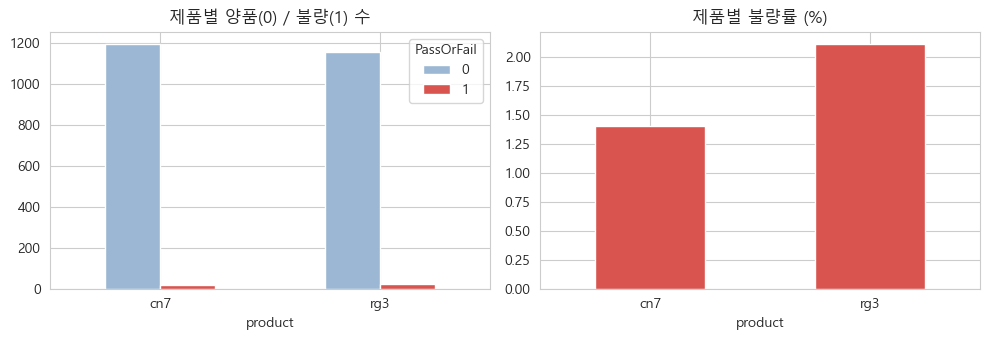

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
cnt = df.groupby(["product", TARGET]).size().unstack()
cnt.plot.bar(ax=ax[0], rot=0, color=["#9bb7d4", "#d9534f"])
ax[0].set_title("제품별 양품(0) / 불량(1) 수")
(df.groupby("product")[TARGET].mean() * 100).plot.bar(ax=ax[1], rot=0, color="#d9534f")
ax[1].set_title("제품별 불량률 (%)")
plt.tight_layout(); plt.show()

In [9]:
r = df.groupby("product")[TARGET].agg(["sum", "size"])
display(Markdown(f"""모두 양품으로 예측해도 정확도가 {100 - df[TARGET].mean()*100:.1f}% 다 (CN7 불량 {r.loc['cn7','sum']}/{r.loc['cn7','size']}, RG3 {r.loc['rg3','sum']}/{r.loc['rg3','size']}).
그래서 정확도는 쓰지 않고, 무작위 기준값이 불량률({df[TARGET].mean():.3f})인 PR-AUC 와 검사량을 고정한 포착률로 비교한다."""))

모두 양품으로 예측해도 정확도가 98.2% 다 (CN7 불량 17/1211, RG3 25/1182).
그래서 정확도는 쓰지 않고, 무작위 기준값이 불량률(0.018)인 PR-AUC 와 검사량을 고정한 포착률로 비교한다.

### 1-2. 추정 사출 그룹과 추정 캐비티
원본에 사출 번호와 캐비티 번호가 없어 다음 규칙으로 추정한다.
1. 연속으로 공정값이 같은 행은 같은 그룹 (연속 2행)
2. 짝이 없는 1행끼리 5행 이내에서 공정값이 완전히 같으면 같은 그룹 (A·B·A·B 처럼 교차 기록된 경우)
3. 추정 캐비티는 그룹 안의 행 순서(0, 1). 실제 금형 캐비티 위치라는 근거는 없다.

공정값이 같은 두 행이 학습과 평가에 나뉘면 정답이 새므로, 모든 분할은 이 그룹 단위로 한다.

In [10]:
st_sum = pd.read_csv(OUT_DIR / "structure_summary.csv")
display(st_sum.set_index("product").T)
print("■ 그룹 유형별 행 수 · 불량 수")
display(df.groupby(["product", "pair_type"]).agg(행수=(TARGET, "size"), 불량=(TARGET, "sum")).unstack(0))
print("■ 추정 캐비티별 불량 (2행 그룹만)")
cav = pd.crosstab([df.loc[df.shot_size == 2, "product"], df.loc[df.shot_size == 2, "cavity"]], df.loc[df.shot_size == 2, TARGET])
cav["불량률(%)"] = (cav[1] / cav.sum(axis=1) * 100).round(2)
display(cav)

product,cn7,rg3
행 수,1211,1182
순번 범위,0~1210,1211~2392
순번 누락 위치 수,0,0
누락된 순번 수,0,0
[연속 규칙] 그룹 수,641,608
[연속 규칙] 2행 그룹,570,574
[연속 규칙] 1행 그룹,71,34
[연속 규칙] 3행 이상,0,0
1행 그룹 중 5행 이내 같은 공정값 짝 있음,70,34
1행 그룹 중 인접 순번 누락,0,0


■ 그룹 유형별 행 수 · 불량 수


행수       불량    
product    cn7  rg3 cn7 rg3
pair_type                  
교차 2행(병합)   70   34   0   0
단일           1  NaN   0 NaN
연속 2행     1140 1148  17  25

■ 추정 캐비티별 불량 (2행 그룹만)


PassOrFail        0   1  불량률(%)
product cavity                 
cn7     0       592  13    2.15
        1       601   4    0.66
rg3     0       568  23    3.89
        1       589   2    0.34

In [11]:
s = st_sum.set_index("product")
sg = pd.read_csv(OUT_DIR / "single_groups.csv")
fc = df[df[TARGET] == 1].groupby("cavity").size()
tw = df[df.pair_type == "교차 2행(병합)"].groupby("product").size() // 2
display(Markdown(f"""연속 규칙만 쓰면 1행 그룹이 CN7 {int(s.loc['cn7','[연속 규칙] 1행 그룹'])}개, RG3 {int(s.loc['rg3','[연속 규칙] 1행 그룹'])}개 생긴다. 이 중 CN7 {int(s.loc['cn7','1행 그룹 중 5행 이내 같은 공정값 짝 있음'])}개, RG3 {int(s.loc['rg3','1행 그룹 중 5행 이내 같은 공정값 짝 있음'])}개는 2~5행 떨어진 곳에 공정값이 완전히 같은 짝이 있어 교차 기록된 사출로 보고 병합했다(CN7 {tw.get('cn7',0)}쌍, RG3 {tw.get('rg3',0)}쌍). 끝까지 짝이 없는 행은 {int((df.pair_type=='단일').sum())}개, 1행 그룹의 불량은 {int(s['1행 그룹 불량'].sum())}건이다.
생산 순번 누락은 {int(s['누락된 순번 수'].sum())}건이므로 1행 그룹은 결측 행 때문에 생긴 것이 아니다. 불량 {int(df[TARGET].sum())}건은 모두 연속 2행 그룹에 있고, 그중 {int(fc.get(0,0))}건({fc.get(0,0)/fc.sum()*100:.0f}%)이 추정 캐비티 0 이다.

한쪽 캐비티에 불량이 몰렸을 가능성이 있지만, 행 순서가 실제 캐비티 위치와 같은지는 확인할 수 없다. 교차 짝 병합도 '5행 이내 완전 일치'라는 가정에 기댄다.
설비에서 사출 번호와 캐비티 번호를 함께 기록하면 이런 추정이 필요 없다. 추정 캐비티 없이 쓰는 모델의 성능은 1-2-1 에서 본다."""))

연속 규칙만 쓰면 1행 그룹이 CN7 71개, RG3 34개 생긴다. 이 중 CN7 70개, RG3 34개는 2~5행 떨어진 곳에 공정값이 완전히 같은 짝이 있어 교차 기록된 사출로 보고 병합했다(CN7 35쌍, RG3 17쌍). 끝까지 짝이 없는 행은 1개, 1행 그룹의 불량은 0건이다.
생산 순번 누락은 0건이므로 1행 그룹은 결측 행 때문에 생긴 것이 아니다. 불량 42건은 모두 연속 2행 그룹에 있고, 그중 36건(86%)이 추정 캐비티 0 이다.

한쪽 캐비티에 불량이 몰렸을 가능성이 있지만, 행 순서가 실제 캐비티 위치와 같은지는 확인할 수 없다. 교차 짝 병합도 '5행 이내 완전 일치'라는 가정에 기댄다.
설비에서 사출 번호와 캐비티 번호를 함께 기록하면 이런 추정이 필요 없다. 추정 캐비티 없이 쓰는 모델의 성능은 1-2-1 에서 본다.

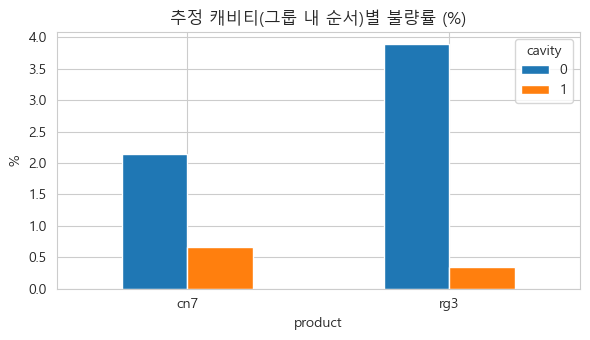

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
(df.groupby(["product", "cavity"])[TARGET].mean() * 100).unstack().plot.bar(ax=ax, rot=0)
ax.set_title("추정 캐비티(그룹 내 순서)별 불량률 (%)"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

### 1-2-1. 추정 캐비티 의존도
추정 캐비티를 넣은 모델(process+cavity)과 뺀 모델(process_only)을 같은 25개 fold 에서 비교한다.
운영 데이터에서 캐비티 순서를 얻을 수 없으면 process_only 모델을 써야 하므로, 그때의 성능 손실을 확인해 둔다.

In [13]:
cv = pd.read_csv(OUT_DIR / "cv_folds.csv")
cav_dep = (cv[cv.scope == "all"].pivot_table(index="model", columns="features", values=["PR_AUC", "Recall@20%"], aggfunc="mean"))
for m in ["PR_AUC", "Recall@20%"]:
    cav_dep[(m, "차이(+cavity − only)")] = cav_dep[(m, "process+cavity")] - cav_dep[(m, "process_only")]
display(cav_dep.round(3))

PR_AUC                  Recall@20%                          PR_AUC         Recall@20%
features       process+cavity process_only process+cavity process_only 차이(+cavity − only) 차이(+cavity − only)
model                                                                                                       
CatBoost                0.118        0.071          0.663        0.411              0.047              0.252
ExtraTrees              0.121        0.088            0.7        0.489              0.033               0.21
LR_baseline             0.082        0.053           0.53        0.362              0.028              0.168
LightGBM                0.101        0.071          0.643        0.415               0.03              0.228
RF+ET_ensemble          0.119        0.092          0.694        0.465              0.028              0.229
RandomForest            0.103         0.07          0.589        0.431              0.034              0.158
XGBoost                 0.079        0.057          0.551        0.368              0.021              0.183

In [14]:
dpr = cav_dep[("PR_AUC", "차이(+cavity − only)")]
best_only = cv[(cv.scope == "all") & (cv.features == "process_only")].groupby("model")["PR_AUC"].mean()
display(Markdown(f"""추정 캐비티를 넣으면 PR-AUC 가 모델별로 {dpr.min():+.3f}~{dpr.max():+.3f} (평균 {dpr.mean():+.3f}) 달라진다. 캐비티 없이 가장 좋은 조합은 {best_only.idxmax()} {best_only.max():.3f} 이다.

성능의 일부는 '그룹 첫 행에 불량이 많다'는 추정 정보에서 나온다. 운영 데이터에서 같은 행 순서가 유지된다는 보장이 없으므로, 캐비티 순서를 얻을 수 없으면 process_only 모델로 운영하고 캐비티 번호가 기록되면 다시 비교한다."""))

추정 캐비티를 넣으면 PR-AUC 가 모델별로 +0.021~+0.047 (평균 +0.032) 달라진다. 캐비티 없이 가장 좋은 조합은 RF+ET_ensemble 0.092 이다.

성능의 일부는 '그룹 첫 행에 불량이 많다'는 추정 정보에서 나온다. 운영 데이터에서 같은 행 순서가 유지된다는 보장이 없으므로, 캐비티 순서를 얻을 수 없으면 process_only 모델로 운영하고 캐비티 번호가 기록되면 다시 비교한다.

### 1-3. 라벨 충돌
같은 공정값 패턴 안에 양품과 불량이 함께 있으면 공정변수만으로는 둘을 구분할 수 없다.

In [15]:
rows = []
for p, d in df.groupby("product"):
    pat = d.groupby(FEATS)[TARGET].agg(["size", "nunique", "sum"])
    rows.append({"product": p,
                 "불량 수": int(d[TARGET].sum()),
                 "충돌 패턴 내 불량": int(pat.loc[pat["nunique"] > 1, "sum"].sum()),
                 "순수 불량 패턴": int((pat["sum"] == pat["size"]).sum())})
pd.DataFrame(rows)

,product,불량 수,충돌 패턴 내 불량,순수 불량 패턴
0,cn7,17,11,3
1,rg3,25,25,0


In [16]:
cf = pd.DataFrame(rows).set_index("product")
display(Markdown(f"""RG3 불량 {cf.loc['rg3','불량 수']}건 중 {cf.loc['rg3','충돌 패턴 내 불량']}건이 같은 공정값 패턴 안에 양품이 함께 있는 충돌 불량이다 (CN7 은 {cf.loc['cn7','충돌 패턴 내 불량']}/{cf.loc['cn7','불량 수']}건).
RG3 불량은 주어진 24개 공정변수로 양품과 구분할 수 없는 경우가 대부분이므로, RG3 의 낮은 성능은 데이터의 예측 상한으로 본다. RG3 에는 모델 단독보다 샘플 검사 규칙과 추가 센서 수집을 함께 제안한다."""))

RG3 불량 25건 중 25건이 같은 공정값 패턴 안에 양품이 함께 있는 충돌 불량이다 (CN7 은 11/17건).
RG3 불량은 주어진 24개 공정변수로 양품과 구분할 수 없는 경우가 대부분이므로, RG3 의 낮은 성능은 데이터의 예측 상한으로 본다. RG3 에는 모델 단독보다 샘플 검사 규칙과 추가 센서 수집을 함께 제안한다.

### 1-4. 데이터 품질 요약
결측, 중복, 상수, 극단값, 라벨 충돌의 규모와 처리 방침이다. 불량 신호일 수 있는 극단값과 충돌 행은 삭제하지 않았다.

In [17]:
display(pd.read_csv(OUT_DIR / "data_quality.csv"))
print("■ 파일별 평균·표준편차 (표준화 여부 관찰용)")
display(pd.read_csv(OUT_DIR / "scaling_check.csv"))

,product,항목,규모,불량 관련,처리
0,cn7,결측,0,-,없음 (결측 0)
1,cn7,상수 열,1,Clamp_Open_Position,"정보 없음 → 입력에서 제외 (학습 데이터 기준으로 결정, 평가 데이터에 같은 열 ..."
2,cn7,공정값 중복 행(순번 제외),1210,불량 17건,"삭제하지 않음: 대부분 같은 추정 사출 그룹의 짝 행이며, 그룹 CV 로 누수를 막음"
3,cn7,극단값 행 (|z|>4),18,불량 6건 (불량률 33.3%),삭제하지 않음: 불량률이 전체보다 높아 불량 신호일 수 있음
4,cn7,라벨 충돌 행 (같은 공정값에 양품·불량 공존),22,불량 11/17건,삭제·수정하지 않음: 공정변수만으로 구분 불가한 불량 → 예측 상한으로 해석
5,rg3,결측,0,-,없음 (결측 0)
6,rg3,상수 열,1,Clamp_Open_Position,"정보 없음 → 입력에서 제외 (학습 데이터 기준으로 결정, 평가 데이터에 같은 열 ..."
7,rg3,공정값 중복 행(순번 제외),1182,불량 25건,"삭제하지 않음: 대부분 같은 추정 사출 그룹의 짝 행이며, 그룹 CV 로 누수를 막음"
8,rg3,극단값 행 (|z|>4),32,불량 0건 (불량률 0.0%),"삭제하지 않음: 불량과 무관해 보이나 측정 오류 근거가 없고, 트리 모델은 극단값에 강건"
9,rg3,라벨 충돌 행 (같은 공정값에 양품·불량 공존),50,불량 25/25건,삭제·수정하지 않음: 공정변수만으로 구분 불가한 불량 → 예측 상한으로 해석


■ 파일별 평균·표준편차 (표준화 여부 관찰용)


,product,set,rows,max_abs_mean,min_std,max_std
0,cn7,labeled,1211,4.631e-12,0,1
1,cn7,unlabeled,35239,9.872e-15,1,1
2,rg3,labeled,1182,2.789e-12,0,1
3,rg3,unlabeled,35941,7.073e-15,1,1


### 1-4-1. 사출 공정 단계별 변수와 이상치
공정변수 24개를 사출 단계(가소화, 충전, 보압, 냉각, 형개폐)로 묶어 불량과의 관련을 본다.
상수 컬럼은 제거하고, 이상치는 표준화 값 |z| > 4 로 세되 제거 여부는 해당 행의 불량률을 보고 정한다.

In [18]:
stages = pd.read_csv(OUT_DIR / "variable_stages.csv")
display(stages.round(2))
outl = pd.read_csv(OUT_DIR / "outliers.csv")
display(outl[outl["|z|>4 행 수"] > 0].round(3))

,단계,변수,고유값 수,CN7 불량-양품 차이,RG3 불량-양품 차이,처리
0,가소화(계량),Plasticizing_Time,61,-0.44,0.18,사용
1,가소화(계량),Plasticizing_Position,21,1.52,-0.1,사용
2,가소화(계량),Max_Screw_RPM,12,-0.25,0.14,사용
3,가소화(계량),Average_Screw_RPM,11,-0.2,0.14,사용
4,가소화(계량),Max_Back_Pressure,41,-1.5,0.08,사용
5,가소화(계량),Average_Back_Pressure,36,-1.36,0.06,사용
6,가소화(계량),Hopper_Temperature,99,-0.68,-0.14,사용
7,가소화(계량),Barrel_Temperature_1,50,-0.18,-0.12,사용
8,가소화(계량),Barrel_Temperature_2,46,-0.26,-0.05,사용
9,가소화(계량),Barrel_Temperature_3,36,0.04,-0.14,사용


,변수,|z|>4 행 수,해당 행 불량,해당 행 불량률,최대 |z|
0,Injection_Time,22,2,0.091,8.628
1,Cycle_Time,12,0,0,12.56
2,Max_Injection_Speed,10,6,0.6,9.556
3,Filling_Time,10,6,0.6,7.777
4,Max_Switch_Over_Pressure,8,0,0,13.79
5,Average_Screw_RPM,6,0,0,16.09
6,Plasticizing_Time,6,0,0,20.04
7,Barrel_Temperature_5,6,0,0,4.608
8,Max_Injection_Pressure,4,0,0,10.86
9,Cushion_Position,2,0,0,6.944


In [19]:
st_eff = stages.assign(abs_cn7=stages["CN7 불량-양품 차이"].abs()).groupby("단계")["abs_cn7"].max().sort_values(ascending=False)
o = outl[outl["|z|>4 행 수"] > 0]
n_out = int(o["|z|>4 행 수"].sum()); f_out = int(o["해당 행 불량"].sum())
const = stages.loc[stages["처리"] != "사용", "변수"].tolist()
display(Markdown(f"""상수 컬럼은 {", ".join(const)} 하나다. CN7 에서 불량-양품 차이가 큰 단계는 {st_eff.index[0]}({st_eff.iloc[0]:.2f}σ), {st_eff.index[1]}({st_eff.iloc[1]:.2f}σ) 순이고, RG3 는 모든 단계에서 0.5σ 안팎이다.
|z|>4 이상치는 {len(o)}개 변수에서 {n_out}건(중복 포함)이고 그중 불량이 {f_out}건(불량률 {f_out/max(1,n_out)*100:.0f}%)으로 전체 불량률({df[TARGET].mean()*100:.1f}%)보다 훨씬 높다.

상수 컬럼만 빼고 이상치는 그대로 둔다. 극단값이 가동 초기 불안정과 함께 나타나는 불량 신호이고, 트리 모델은 극단값에 강건하다."""))

상수 컬럼은 Clamp_Open_Position 하나다. CN7 에서 불량-양품 차이가 큰 단계는 충전(사출)(2.77σ), 가소화(계량)(1.52σ) 순이고, RG3 는 모든 단계에서 0.5σ 안팎이다.
|z|>4 이상치는 11개 변수에서 88건(중복 포함)이고 그중 불량이 14건(불량률 16%)으로 전체 불량률(1.8%)보다 훨씬 높다.

상수 컬럼만 빼고 이상치는 그대로 둔다. 극단값이 가동 초기 불안정과 함께 나타나는 불량 신호이고, 트리 모델은 극단값에 강건하다.

### 1-4-2. 비라벨 데이터 결합 가능성 (부가 실험)
비라벨 7만 행을 학습에 쓸 수 있는지 두 실험으로 확인한다. 분포가 왜 다른지(기간, 설비 조건, 전처리)는 자료로 확인되지 않았다.
- 도메인 판별: 라벨 행과 비라벨 행을 구분하는 분류기의 AUC. 0.5 면 비슷한 분포, 1.0 이면 완전히 구분된다. `rank` 는 파일별 순위 변환 후 결과.
- 자기학습: 라벨 모델이 비라벨에 매긴 점수 상·하위를 가짜 라벨로 추가해 재학습하고, 같은 fold 에서 라벨만 쓴 모델과 비교.

In [20]:
if has_extra("self_training_cv.csv"):
    display(pd.read_csv(OUT_DIR / "unlabeled_domain_auc.csv").round(3))

    st = pd.read_csv(OUT_DIR / "self_training_cv.csv")
    cols = ["PR_AUC_all", "PR_AUC_cn7", "PR_AUC_rg3", "Recall@20%"]
    display(st.groupby("method")[cols].agg(["mean", "std"]).round(3))
    print("비라벨 평균 예측 불량확률: %.3f  (라벨 데이터 불량률 %.3f)"
          % (st["unlabeled_mean_prob"].mean(), df[TARGET].mean()))

,product,transform,domain_AUC
0,cn7,raw,1
1,cn7,rank,1
2,rg3,raw,1
3,rg3,rank,1


PR_AUC_all       PR_AUC_cn7       PR_AUC_rg3       Recall@20%      
                           mean   std       mean   std       mean   std       mean   std
method                                                                                  
labeled_only              0.098 0.061      0.205 0.132      0.093 0.045      0.617 0.174
self_training_loose       0.128 0.107      0.271 0.272      0.116 0.089      0.512 0.213
self_training_strict      0.136 0.117      0.282 0.257      0.118 0.126      0.649 0.239

비라벨 평균 예측 불량확률: 0.037  (라벨 데이터 불량률 0.018)


In [21]:
if has_extra("unlabeled_domain_auc.csv"):
    dm = pd.read_csv(OUT_DIR / "unlabeled_domain_auc.csv")
    stm = st.groupby("method")["PR_AUC_all"].mean()
    display(Markdown(f"""라벨/비라벨 판별 AUC 는 {dm.domain_AUC.min():.2f}{'' if dm.domain_AUC.min() == dm.domain_AUC.max() else f'~{dm.domain_AUC.max():.2f}'} 이다. 자기학습 PR-AUC 는 {", ".join(f"{k} {v:.3f}" for k, v in stm.items())} 이다.

    두 데이터는 쉽게 구분될 만큼 분포가 다르다. 기간이나 조건 차이, 파일별 표준화가 원인일 수 있으나 확인하지 못했다.
    자기학습이 라벨만 쓴 경우보다 {'높게' if stm.drop('labeled_only').max() > stm['labeled_only'] else '낮게'} 나왔지만(이 실험의 기준 모델은 반복 수가 달라 2장 값과 직접 비교하지 않는다), 분포가 이만큼 다른 데이터의 가짜 라벨로 생긴 변화는 반복 확인 전까지 신뢰하기 어려워 비라벨은 학습에 넣지 않았다. 비라벨은 분포 진단과 운전구간 군집(3-4)에만 쓴다.
    원 단위 데이터와 수집 기간 정보가 있으면 결합 여부를 다시 판단할 수 있다."""))

라벨/비라벨 판별 AUC 는 1.00 이다. 자기학습 PR-AUC 는 labeled_only 0.098, self_training_loose 0.128, self_training_strict 0.136 이다.

두 데이터는 쉽게 구분될 만큼 분포가 다르다. 기간이나 조건 차이, 파일별 표준화가 원인일 수 있으나 확인하지 못했다.
자기학습이 라벨만 쓴 경우보다 높게 나왔지만(이 실험의 기준 모델은 반복 수가 달라 2장 값과 직접 비교하지 않는다), 분포가 이만큼 다른 데이터의 가짜 라벨로 생긴 변화는 반복 확인 전까지 신뢰하기 어려워 비라벨은 학습에 넣지 않았다. 비라벨은 분포 진단과 운전구간 군집(3-4)에만 쓴다.
원 단위 데이터와 수집 기간 정보가 있으면 결합 여부를 다시 판단할 수 있다.

### 1-5. 시간(생산 순번)에 따른 불량 분포

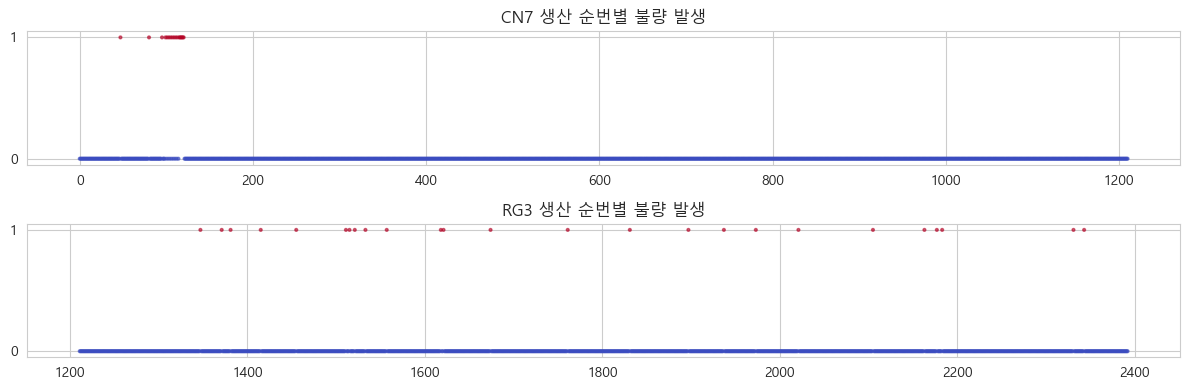

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharey=True)
for ax, (p, d) in zip(axes, df.groupby("product")):
    ax.scatter(d[INDEX_COL], d[TARGET], s=4, alpha=.6, c=d[TARGET], cmap="coolwarm")
    ax.set_title(f"{p.upper()} 생산 순번별 불량 발생"); ax.set_yticks([0, 1])
plt.tight_layout(); plt.show()

In [23]:
fi = df[(df["product"] == "cn7") & (df[TARGET] == 1)].sort_values(INDEX_COL)
pos = df[df["product"] == "cn7"].sort_values(INDEX_COL).reset_index(drop=True)
order = pos.index[pos[TARGET] == 1]
display(Markdown(f"""CN7 불량 {len(fi)}건은 생산 순번 {fi[INDEX_COL].min()}~{fi[INDEX_COL].max()} (제품 내 {order.min()+1}~{order.max()+1}번째 행)에 몰려 있어 가동 초기 불안정 구간으로 보인다. RG3 불량은 전 구간에 흩어져 있다.

무작위 사출 그룹 CV 는 같은 시기 사출이 학습에 들어가 낙관적일 수 있으므로, 생산순번 블록 CV 와 과거→미래 대리 검증(2-8)을 함께 보고, 가동 초기 강화검사 규칙과도 비교한다(4-1)."""))

CN7 불량 17건은 생산 순번 47~120 (제품 내 48~121번째 행)에 몰려 있어 가동 초기 불안정 구간으로 보인다. RG3 불량은 전 구간에 흩어져 있다.

무작위 사출 그룹 CV 는 같은 시기 사출이 학습에 들어가 낙관적일 수 있으므로, 생산순번 블록 CV 와 과거→미래 대리 검증(2-8)을 함께 보고, 가동 초기 강화검사 규칙과도 비교한다(4-1).

### 1-6. 양품 vs 불량 공정변수 분포

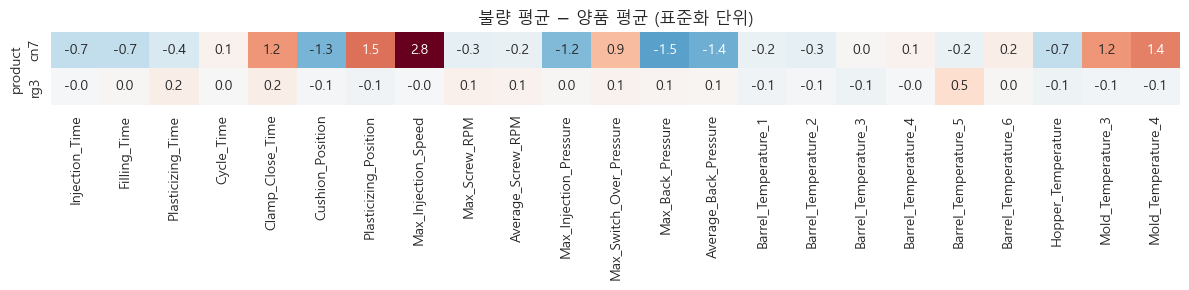

In [24]:
use = [c for c in FEATS if df[c].nunique() > 1]
diff = (df.groupby(["product", TARGET])[use].mean()
          .groupby(level=0).diff().dropna().droplevel(1))
fig, ax = plt.subplots(figsize=(12, 3))
sns.heatmap(diff, cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax, cbar=False)
ax.set_title("불량 평균 − 양품 평균 (표준화 단위)")
plt.tight_layout(); plt.show()

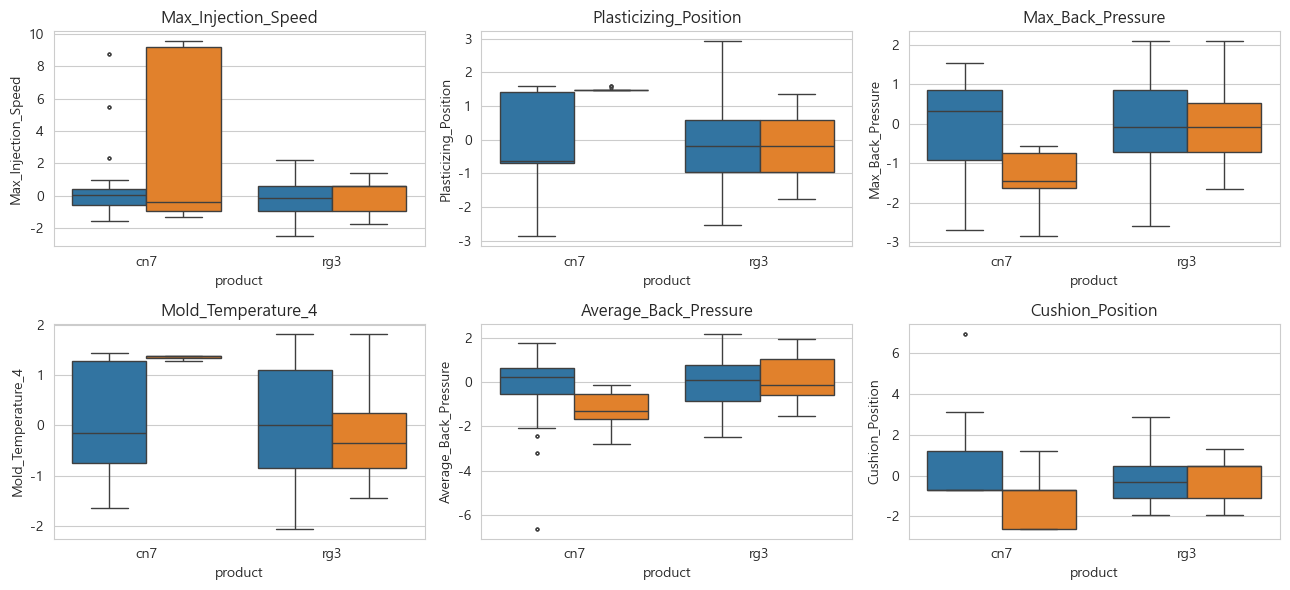

In [25]:
top = diff.abs().max().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), top):
    sns.boxplot(data=df, x="product", y=c, hue=TARGET, ax=ax, fliersize=2)
    ax.set_title(c); ax.legend_.remove()
plt.tight_layout(); plt.show()

In [26]:
dd = diff.T
c7 = dd["cn7"].abs().sort_values(ascending=False)
r3 = dd["rg3"].abs().sort_values(ascending=False)
display(Markdown(f"""CN7 은 {c7.index[0]}({dd.loc[c7.index[0],'cn7']:+.2f}σ), {c7.index[1]}({dd.loc[c7.index[1],'cn7']:+.2f}σ), {c7.index[2]}({dd.loc[c7.index[2],'cn7']:+.2f}σ) 등에서 불량과 양품의 평균이 1σ 이상 다르다. RG3 는 가장 큰 차이가 {r3.index[0]} {dd.loc[r3.index[0],'rg3']:+.2f}σ 로 평균만으로는 구분되지 않는다.
단일 변수 관리 기준으로는 RG3 를 잡기 어려워 변수 조합을 학습하는 트리 계열 모델을 쓰고, 제품 구분 변수(is_rg3)를 넣어 두 제품을 한 모델로 학습한다."""))

CN7 은 Max_Injection_Speed(+2.77σ), Plasticizing_Position(+1.52σ), Max_Back_Pressure(-1.50σ) 등에서 불량과 양품의 평균이 1σ 이상 다르다. RG3 는 가장 큰 차이가 Barrel_Temperature_5 +0.46σ 로 평균만으로는 구분되지 않는다.
단일 변수 관리 기준으로는 RG3 를 잡기 어려워 변수 조합을 학습하는 트리 계열 모델을 쓰고, 제품 구분 변수(is_rg3)를 넣어 두 제품을 한 모델로 학습한다.

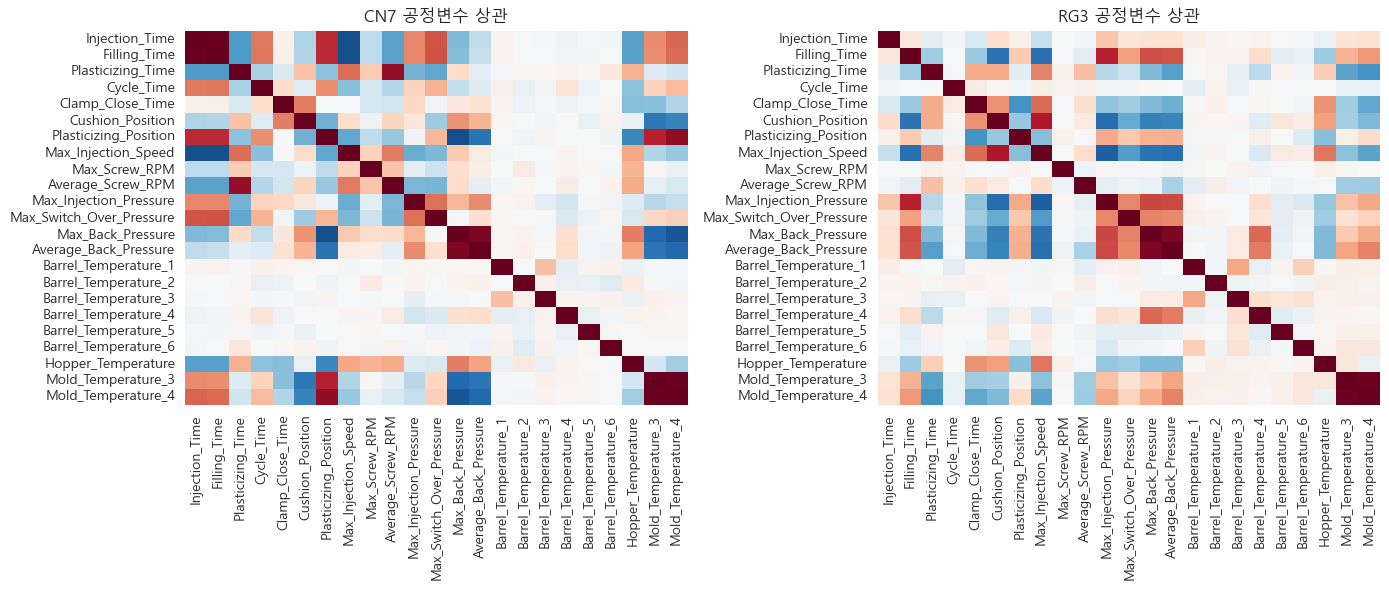

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (p, d) in zip(axes, df.groupby("product")):
    sns.heatmap(d[use].corr(), cmap="RdBu_r", center=0, ax=ax, cbar=False)
    ax.set_title(f"{p.upper()} 공정변수 상관")
plt.tight_layout(); plt.show()

In [28]:
cc = df[df["product"] == "cn7"][use].corr().abs().where(lambda m: np.triu(np.ones(m.shape, bool), 1)).stack()
display(Markdown(f"""CN7 에서 상관계수 0.9 이상인 변수쌍은 {int((cc > 0.9).sum())}개다 ({", ".join(f"{a}–{b}" for a, b in cc[cc > 0.9].index)}). 같은 사출 단계 안의 변수끼리 함께 움직인다.
선형모델은 베이스라인으로만 쓰고 주 모델은 트리 앙상블로 한다. 상관 변수끼리는 중요도가 나뉘므로 SHAP 결과(3-1)는 단계 단위로도 묶어 본다."""))

CN7 에서 상관계수 0.9 이상인 변수쌍은 3개다 (Injection_Time–Filling_Time, Max_Back_Pressure–Average_Back_Pressure, Mold_Temperature_3–Mold_Temperature_4). 같은 사출 단계 안의 변수끼리 함께 움직인다.
선형모델은 베이스라인으로만 쓰고 주 모델은 트리 앙상블로 한다. 상관 변수끼리는 중요도가 나뉘므로 SHAP 결과(3-1)는 단계 단위로도 묶어 본다.

## 2. AI 예측모델 개발 및 성능평가

모든 분할은 추정 사출 그룹 단위이며, 입력 열 선택, 임계값, 확률 보정, 스태킹 메타 학습은 각 학습 데이터 안에서만 정한다.

| 검증 | 분할 방식 | 보는 것 | 한계 |
|---|---|---|---|
| ① 무작위 사출 그룹 CV (주 검증, 5-fold × 5회) | 사출 그룹을 무작위로 fold 배정 | 같은 생산 기간 안에서의 일반화 | 같은 시기 이웃 사출이 학습에 들어가 낙관적일 수 있음 |
| ② 생산순번 블록 CV (8·16 블록) | 연속 생산 구간을 통째로 평가 | 같은 시기 사출을 학습에서 뺐을 때 | 평가 구간 뒤의 구간도 학습에 쓰여 시간 순서를 지키지 않음 |
| ③ 과거→미래 대리 검증 (5구간 expanding window) | 앞 구간으로 학습, 다음 구간 평가 | 시간 순서를 지킨 운영 상황 | 실제 시각이 아닌 생산 순번 기준, 불량 없는 구간은 평가 불가 |

- 테스트셋: 사출 그룹·불량 층화로 20% 분리. 모델 선정과 설정 변경에 쓰지 않았다.
- 최종모델 선정 규칙(분석 전에 정함): 개발셋 ① 의 전체 PR-AUC 평균이 가장 높은 조합. 후보는 모델 7종 × 특성셋 2종. 클래스 가중치는 고정 설계값이며 2-6 에서 민감도를 확인한다.
- 하이퍼파라미터: 탐색하지 않고 과적합을 줄이는 방향의 값으로 고정했다(배깅은 잎 최소 2개, 부스팅은 얕은 깊이·낮은 학습률·L2 규제, 설정은 `src/models.py`). fold 당 평가 불량이 6~7건이라 내부 CV 로 조합을 고르면 선택이 잡음에 좌우되고(같은 조합의 fold 간 PR-AUC 표준편차 약 0.1), 불량 34건으로 튜닝하면 검증 성능이 낙관적으로 부풀기 쉽다. 대신 모델 간 차이가 통계적으로 구분되는지(2-5)를 보고했다. 데이터가 늘면 중첩 그룹 CV 로 튜닝하는 것을 향후 과제로 둔다.
- 지표: PR-AUC(순위 품질), Recall@k%(검사 용량 k% 에서의 포착률), 운영점 F1@20%. 임계값 F1 은 fold 당 불량 6~7건이라 불안정해 선정에 쓰지 않는다.
- 계산 방식: 2장의 Recall@k%·F1@20% 는 25개 평가 fold 값의 평균(fold 평균)이고, 4장 검사 용량표는 개발셋 전체 OOF 점수를 제품별 상위 k% 로 검사해 합산한 건수(OOF 합산)라 값이 조금 다르다.

### 2-0. 표본 규모와 분할 누수 점검

In [29]:
display(pd.read_csv(OUT_DIR / "sample_counts.csv").round(4))
display(pd.read_csv(OUT_DIR / "split_audit.csv"))

,set,scope,행 수,추정 사출 그룹 수,불량 수,불량률
0,dev,all,1909,955,34,0.0178
1,dev,cn7,965,483,13,0.0135
2,dev,rg3,944,472,21,0.0222
3,test,all,484,242,8,0.0165
4,test,cn7,246,123,4,0.0163
5,test,rg3,238,119,4,0.0168


,분할,검사한 분할 수,겹친 그룹 수,결과
0,개발 / 테스트 (홀드아웃),1,0,통과
1,개발 / 테스트 (같은 공정값 행 기준),1,0,통과
2,외부 CV (5회 × 5-fold),25,0,통과
3,내부 3-fold (임계값 선정·확률 보정·스태킹 메타 학습),75,0,통과
4,생산순번 블록 5개: 그룹이 두 블록에 걸침,1,0,통과
5,생산순번 블록 8개: 그룹이 두 블록에 걸침,1,0,통과
6,생산순번 블록 16개: 그룹이 두 블록에 걸침,1,0,통과


In [30]:
MET = ["PR_AUC", "ROC_AUC", "F1", "Precision", "Recall", "Recall@5%", "Recall@10%", "Recall@20%"]
summary = cv.groupby(["scope", "features", "model"])[MET].agg(["mean", "std"]).round(3)
print("fold 당 평가 규모 (평균):", cv.groupby("scope")[["n_rows", "n_shots", "n_fail"]].mean().round(1).to_dict("index"))
na_folds = cv[cv.note.fillna("") != ""]
print(f"불량 0건이라 지표를 정의할 수 없는 (fold, 범위): {len(na_folds)}개", na_folds.groupby("scope").size().to_dict())
summary.loc["all"]

fold 당 평가 규모 (평균): {'all': {'n_rows': 381.8, 'n_shots': 191.0, 'n_fail': 6.8}, 'cn7': {'n_rows': 193.0, 'n_shots': 96.6, 'n_fail': 2.6}, 'rg3': {'n_rows': 188.8, 'n_shots': 94.4, 'n_fail': 4.2}}
불량 0건이라 지표를 정의할 수 없는 (fold, 범위): 56개 {'cn7': 56}


PR_AUC       ROC_AUC          F1       Precision       Recall       Recall@5%       Recall@10%       Recall@20%      
                                mean   std    mean   std  mean   std      mean   std   mean   std      mean   std       mean   std       mean   std
features       model                                                                                                                               
process+cavity CatBoost        0.118 0.075   0.831 0.077 0.113 0.085     0.087 0.093  0.328 0.286     0.205 0.146       0.44 0.235      0.663 0.186
               ExtraTrees      0.121  0.11   0.845  0.06 0.057 0.072     0.035 0.045  0.244 0.334      0.21 0.136       0.48 0.221        0.7 0.195
               LR_baseline     0.082 0.056    0.77 0.122 0.061 0.065     0.038 0.041  0.196 0.237     0.172 0.149      0.357 0.199       0.53 0.263
               LightGBM        0.101 0.069   0.816 0.077 0.084 0.071     0.058 0.059  0.276 0.293     0.203  0.19      0.363 0.169      0.643 0.183
               RF+ET_ensemble  0.119   0.1    0.84 0.062 0.072 0.094     0.048  0.07  0.217 0.318      0.23 0.163      0.415 0.205      0.694 0.209
               RandomForest    0.103 0.072   0.807 0.066 0.095 0.086     0.064 0.061  0.257 0.264     0.241 0.166      0.399 0.189      0.589   0.2
               XGBoost         0.079 0.051   0.784 0.082 0.095 0.064     0.067 0.057  0.333  0.25     0.164 0.127      0.303 0.188      0.551 0.215
process_only   CatBoost        0.071 0.055    0.74 0.076 0.071 0.062     0.055 0.063  0.253 0.306     0.143 0.158      0.256 0.173      0.411 0.214
               ExtraTrees      0.088 0.108   0.759 0.067 0.024 0.045     0.015 0.028  0.137 0.274     0.084 0.131      0.231 0.153      0.489 0.176
               LR_baseline     0.053 0.054   0.662 0.126 0.028 0.049     0.016  0.03  0.149 0.255     0.077 0.125      0.166 0.165      0.362 0.188
               LightGBM        0.071 0.058   0.687 0.098 0.053 0.061     0.035 0.043  0.173 0.231     0.143 0.145       0.26 0.193      0.415 0.221
               RF+ET_ensemble  0.092 0.107   0.759 0.069 0.036 0.048     0.021 0.028  0.197 0.306     0.108  0.14      0.215 0.191      0.465 0.199
               RandomForest     0.07 0.063   0.748 0.068 0.063 0.066     0.042  0.05  0.235 0.285     0.128  0.15      0.251 0.175      0.431 0.178
               XGBoost         0.057 0.066   0.682 0.089  0.05 0.069     0.032  0.05  0.207 0.258      0.13 0.115      0.175 0.121      0.368 0.183

In [31]:
s = cv[cv.scope == "all"].groupby(["model", "features"])[["PR_AUC", "Recall@20%"]].mean()
top3 = s.sort_values("PR_AUC", ascending=False).head(3)
sd = cv[cv.scope == "all"].groupby(["model", "features"])["PR_AUC"].std().mean()
display(Markdown(f"""PR-AUC 상위 3개는 {", ".join(f"{m}/{f} {v:.3f}" for (m, f), v in top3.PR_AUC.items())} 이다 (무작위 {df[TARGET].mean():.3f}). 1위와 3위의 차이({top3.PR_AUC.iloc[0] - top3.PR_AUC.iloc[2]:.3f})는 fold 간 표준편차 평균({sd:.3f})보다 작다. 트리 계열은 LR 베이스라인보다 일관되게 높다.
평균 하나로 우열을 정하지 않고, 짝 비교 유의성(2-5)과 운영 지표(2-9)를 함께 본다."""))

PR-AUC 상위 3개는 ExtraTrees/process+cavity 0.121, RF+ET_ensemble/process+cavity 0.119, CatBoost/process+cavity 0.118 이다 (무작위 0.018). 1위와 3위의 차이(0.003)는 fold 간 표준편차 평균(0.075)보다 작다. 트리 계열은 LR 베이스라인보다 일관되게 높다.
평균 하나로 우열을 정하지 않고, 짝 비교 유의성(2-5)과 운영 지표(2-9)를 함께 본다.

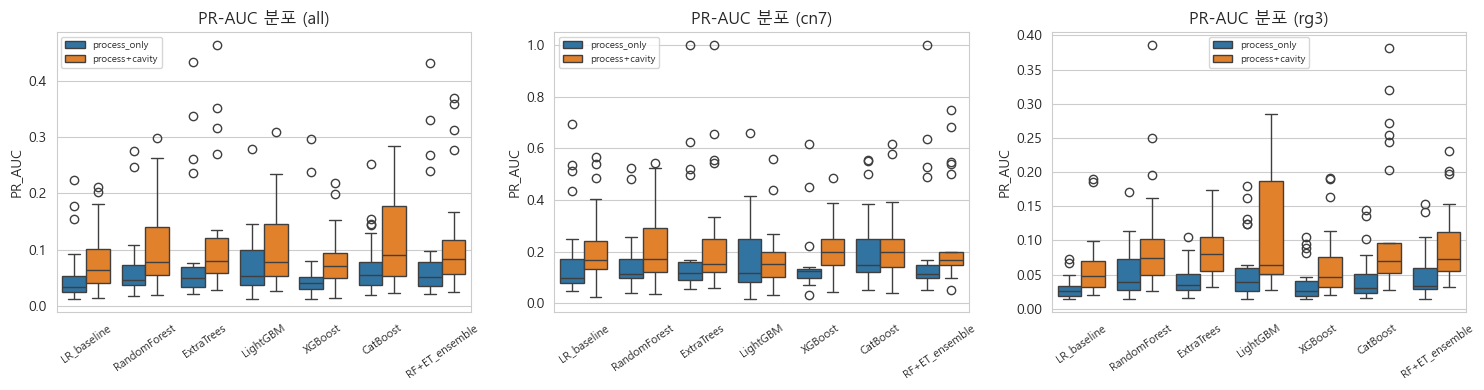

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, sc in zip(axes, ["all", "cn7", "rg3"]):
    sns.boxplot(data=cv[cv.scope == sc], x="model", y="PR_AUC", hue="features", ax=ax)
    ax.set_title(f"PR-AUC 분포 ({sc})"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35, labelsize=8); ax.legend(fontsize=7, title=None)
plt.tight_layout(); plt.show()

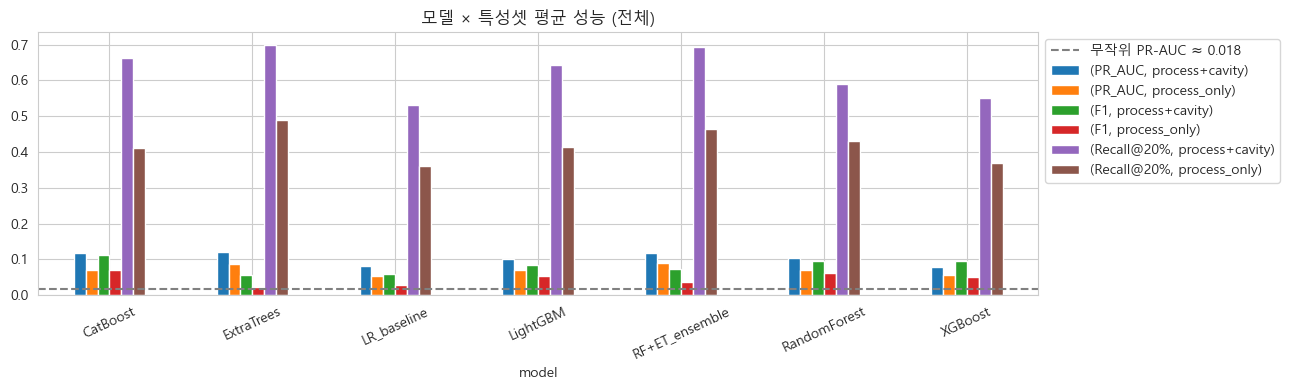

In [33]:
base = df[TARGET].mean()
tbl = cv[cv.scope == "all"].groupby(["model", "features"])[["PR_AUC", "F1", "Recall@20%"]].mean().unstack()
tbl.plot.bar(figsize=(13, 4), rot=25)
plt.axhline(base, ls="--", c="gray", label=f"무작위 PR-AUC ≈ {base:.3f}")
plt.title("모델 × 특성셋 평균 성능 (전체)"); plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

In [34]:
f = cv[cv.scope == "all"].groupby(["model", "features"])[["F1", "F1@20%"]].mean()
display(Markdown(f"""임계값 기준 F1 은 모델마다 {f.F1.min():.3f}~{f.F1.max():.3f} 로 크게 흔들린다. fold 당 불량이 6~7건이라 학습 fold 안에서 고른 임계값이 평가 fold 에 잘 맞지 않는다. 검사량을 고정한 운영점 F1@20% 는 {f['F1@20%'].min():.3f}~{f['F1@20%'].max():.3f} 로 더 안정적이다.
그래서 임계값 F1 은 참고로만 두고 순위 지표와 운영점 F1 으로 평가한다."""))

임계값 기준 F1 은 모델마다 0.024~0.113 로 크게 흔들린다. fold 당 불량이 6~7건이라 학습 fold 안에서 고른 임계값이 평가 fold 에 잘 맞지 않는다. 검사량을 고정한 운영점 F1@20% 는 0.057~0.110 로 더 안정적이다.
그래서 임계값 F1 은 참고로만 두고 순위 지표와 운영점 F1 으로 평가한다.

### 2-1. 최종모델과 테스트 성능
최종모델은 위 규칙으로 개발셋에서 정했다. 테스트 성능은 사출 그룹 단위 부트스트랩 95% 신뢰구간과 함께 본다.

In [35]:
allscope = cv[cv.scope == "all"].groupby(["model", "features"])["PR_AUC"].mean()
BEST_MODEL, BEST_FS = allscope.idxmax()
USE_CAV = BEST_FS == "process+cavity"
print(f"최종모델: {BEST_MODEL} / {BEST_FS}  (CV PR-AUC {allscope.max():.3f})")

dev, test = holdout_split(df)
FCOLS = feature_columns(dev)   # 개발셋 기준 입력 열
X_dev, X_test = feature_matrix(dev, USE_CAV, FCOLS), feature_matrix(test, USE_CAV, FCOLS)
y_dev, y_test = dev[TARGET].to_numpy(), test[TARGET].to_numpy()

model = get_models()[BEST_MODEL]
THR = best_threshold(y_dev, inner_oof(model, X_dev, y_dev, dev["group"].to_numpy(), SEED))
final = clone(model).fit(X_dev, y_dev)
p_test = final.predict_proba(X_test)[:, 1]

res = {"all": metrics(y_test, p_test, THR)}
for p in ["cn7", "rg3"]:
    m = test["product"].to_numpy() == p
    res[p] = metrics(y_test[m], p_test[m], THR)
print("공통 임계값:", round(THR, 4))
na(pd.DataFrame(res))

최종모델: ExtraTrees / process+cavity  (CV PR-AUC 0.121)


공통 임계값: 0.0525


,all,cn7,rg3
PR_AUC,0.343,0.674,0.017
ROC_AUC,0.781,0.987,0.391
F1,0.067,0.267,0
Precision,0.036,0.154,0
Recall,0.5,1,0
Recall@5%,0.5,1,0
Recall@10%,0.5,1,0
Recall@20%,0.5,1,0
Precision@20%,0.041,0.08,0
F1@20%,0.076,0.148,0


In [36]:
# 테스트 지표 95% 신뢰구간 (사출 그룹 부트스트랩 1000회)
ci = pd.read_csv(OUT_DIR / "test_bootstrap_ci.csv")
ci["95% CI"] = ci.apply(lambda r: f"[{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
display(ci.pivot_table(index="metric", columns="scope", values="point", aggfunc="first").round(3))
display(ci[["scope", "metric", "point", "95% CI", "불량 수", "무작위 PR-AUC", "valid_boot"]].round(3))

scope,all,cn7,rg3
metric,,,
F1(임계값),0.067,0.267,0
PR_AUC,0.343,0.674,0.017
ROC_AUC,0.781,0.987,0.391
Recall@20%,0.5,1,0


,scope,metric,point,95% CI,불량 수,무작위 PR-AUC,valid_boot
0,all,PR_AUC,0.343,"[0.015, 0.706]",8,0.017,1000
1,all,ROC_AUC,0.781,"[0.527, 0.952]",8,0.017,1000
2,all,Recall@20%,0.5,"[0.000, 0.875]",8,0.017,1000
3,all,F1(임계값),0.067,"[0.000, 0.138]",8,0.017,1000
4,cn7,PR_AUC,0.674,"[0.111, 1.000]",4,0.016,956
5,cn7,ROC_AUC,0.987,"[0.959, 1.000]",4,0.016,956
6,cn7,Recall@20%,1,"[1.000, 1.000]",4,0.016,956
7,cn7,F1(임계값),0.267,"[0.074, 0.502]",4,0.016,956
8,rg3,PR_AUC,0.017,"[0.007, 0.042]",4,0.017,978
9,rg3,ROC_AUC,0.391,"[0.076, 0.603]",4,0.017,978


In [37]:
g = ci.set_index(["scope", "metric"])
rg = g.loc[("rg3", "PR_AUC")]; rgr = g.loc[("rg3", "ROC_AUC")]; al = g.loc[("all", "PR_AUC")]
cvm = cv[(cv.model == BEST_MODEL) & (cv.features == BEST_FS)].groupby("scope")["PR_AUC"].mean()
display(Markdown(f"""테스트 불량은 {int(g.loc[('all','PR_AUC'),'불량 수'])}건(CN7 {int(g.loc[('cn7','PR_AUC'),'불량 수'])}, RG3 {int(rg['불량 수'])})뿐이어서 전체 PR-AUC {al.point:.3f} 의 95% 신뢰구간이 [{al.ci_low:.3f}, {al.ci_high:.3f}] 로 넓다. 임계값 기준 F1 은 {res['all']['F1']:.3f}, RG3 Recall 과 Recall@20% 는 {res['rg3']['Recall']:.3f}, {res['rg3']['Recall@20%']:.3f} 이다.
RG3 테스트 PR-AUC 는 {rg.point:.3f}(무작위 {rg['무작위 PR-AUC']:.3f}), ROC-AUC 는 {rgr.point:.3f} 로, 충돌 불량 4건이 어느 쪽에 걸리느냐에 따라 크게 달라지는 값이다.

불량 8건으로는 성능을 확정할 수 없으므로, 결론은 개발셋 CV(전체 {cvm['all']:.3f}, CN7 {cvm['cn7']:.3f}, RG3 {cvm['rg3']:.3f})와 2-8 의 시간 검증을 중심으로 내린다."""))

테스트 불량은 8건(CN7 4, RG3 4)뿐이어서 전체 PR-AUC 0.343 의 95% 신뢰구간이 [0.015, 0.706] 로 넓다. 임계값 기준 F1 은 0.067, RG3 Recall 과 Recall@20% 는 0.000, 0.000 이다.
RG3 테스트 PR-AUC 는 0.017(무작위 0.017), ROC-AUC 는 0.391 로, 충돌 불량 4건이 어느 쪽에 걸리느냐에 따라 크게 달라지는 값이다.

불량 8건으로는 성능을 확정할 수 없으므로, 결론은 개발셋 CV(전체 0.121, CN7 0.258, RG3 0.083)와 2-8 의 시간 검증을 중심으로 내린다.

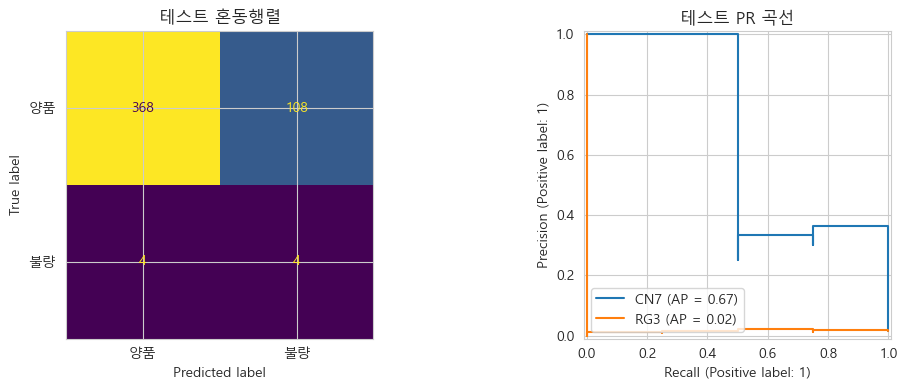

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= THR).astype(int), ax=ax[0],
                                        display_labels=["양품", "불량"], colorbar=False)
ax[0].set_title("테스트 혼동행렬")
for p in ["cn7", "rg3"]:
    m = test["product"].to_numpy() == p
    PrecisionRecallDisplay.from_predictions(y_test[m], p_test[m], ax=ax[1], name=p.upper())
ax[1].set_title("테스트 PR 곡선")
plt.tight_layout(); plt.show()

### 2-1-1. 임계값 판정과 상위 k% 검사
OOF 예측으로 오류표를 만들 때 어떤 기준을 쓰느냐에 따라 결과가 크게 달라진다. 세 가지를 구분한다.
- A. 외부 fold 임계값: 각 fold 의 학습 데이터 안에서 정한 임계값으로 그 fold 를 판정. CV 요약표와 같은 기준이며 반복마다 따로 집계한다.
- B. 반복 평균 점수 + 공통 임계값: 개발셋 전체에서 정한 임계값을 5회 반복 평균 점수에 적용. 반복 평균은 점수 분포를 좁히므로 진단용으로만 본다.
- C. 제품별 상위 20% 검사: 운영 방식. 임계값 대신 순위를 쓴다.

fold 별 점수, 임계값, 판정은 `oof_fold_preds.csv` 에 저장된다.

In [39]:
views = pd.read_csv(OUT_DIR / "oof_threshold_views.csv")
display(views.round(3))
fpd = pd.read_csv(OUT_DIR / "oof_fold_preds.csv")
oof_tmp = pd.read_csv(OUT_DIR / "oof_dev.csv")
print("fold 임계값 분포:", fpd.drop_duplicates(["repeat", "fold"])["fold_threshold"].describe()[["min", "50%", "max"]].round(3).to_dict())
print("반복 평균 점수: 불량 중앙값 %.3f / 최댓값 %.3f, 공통 임계값 %.3f"
      % (oof_tmp.loc[oof_tmp[TARGET] == 1, "oof_prob"].median(), oof_tmp["oof_prob"].max(), THR))

,관점,repeat,TP,FN,FP,TN,임계값,Recall,Precision,검사(양성 판정) 비율
0,A. 외부 fold 임계값 (반복별),0,8,26,99,1776,0.045~0.413,0.235,0.075,0.056
1,A. 외부 fold 임계값 (반복별),1,9,25,143,1732,0.056~0.351,0.265,0.059,0.08
2,A. 외부 fold 임계값 (반복별),2,12,22,205,1670,0.028~0.375,0.353,0.055,0.114
3,A. 외부 fold 임계값 (반복별),3,3,31,100,1775,0.098~0.432,0.088,0.029,0.054
4,A. 외부 fold 임계값 (반복별),4,12,22,117,1758,0.071~0.380,0.353,0.093,0.068
5,B. 반복 평균 점수 + 공통 임계값 (진단용),-,26,8,371,1504,0.052,0.765,0.065,0.208
6,C. 제품별 상위 20% 검사 (운영 기준),-,22,12,360,1515,제품별 순위,0.647,0.058,0.2


fold 임계값 분포: {'min': 0.028, '50%': 0.167, 'max': 0.432}
반복 평균 점수: 불량 중앙값 0.099 / 최댓값 0.411, 공통 임계값 0.052


In [40]:
A = views[views["관점"].str.startswith("A")]
B = views[views["관점"].str.startswith("B")].iloc[0]; Cc = views[views["관점"].str.startswith("C")].iloc[0]
fthr = fpd.drop_duplicates(["repeat", "fold"])["fold_threshold"]
display(Markdown(f"""A(외부 fold 임계값)는 반복별 TP {A.TP.min()}~{A.TP.max()}, FP {A.FP.min()}~{A.FP.max()} 이고, fold 임계값 자체가 {fthr.min():.3f}~{fthr.max():.3f} 로 흩어져 있다. B(반복 평균 점수 + 공통 임계값 {THR:.3f})는 TP {B.TP}, FN {B.FN}, FP {B.FP}, C(제품별 상위 20%)는 TP {Cc.TP}, FN {Cc.FN}, FP {Cc.FP} 다.
B 는 단일 모델 점수로 정한 임계값을 분포가 좁아진 반복 평균 점수에 적용하므로, 임계값이 조금만 달라도 TP 가 크게 바뀐다.

고정 임계값 판정은 이 데이터에서 안정적이지 않다. 운영과 오류분석(3-3)은 C 기준으로 하고, B 는 진단용으로만 둔다."""))

A(외부 fold 임계값)는 반복별 TP 3~12, FP 99~205 이고, fold 임계값 자체가 0.028~0.432 로 흩어져 있다. B(반복 평균 점수 + 공통 임계값 0.052)는 TP 26, FN 8, FP 371, C(제품별 상위 20%)는 TP 22, FN 12, FP 360 다.
B 는 단일 모델 점수로 정한 임계값을 분포가 좁아진 반복 평균 점수에 적용하므로, 임계값이 조금만 달라도 TP 가 크게 바뀐다.

고정 임계값 판정은 이 데이터에서 안정적이지 않다. 운영과 오류분석(3-3)은 C 기준으로 하고, B 는 진단용으로만 둔다.

### 2-2. 확률 보정
보정 곡선으로 모델 출력이 실제 불량 빈도와 맞는지 보고, 같은 25개 fold 에서 보정 없음 / sigmoid / isotonic 을 비교한다.
보정기는 각 학습 fold 안의 사출 그룹 단위 3-fold 로 학습한다. 정확도는 Brier 점수로, 순위 변화는 PR-AUC·Recall@20% 로 본다.
불량이 34건이라 보정 곡선의 구간마다 불량은 몇 건뿐이다.

Brier        PR_AUC        Recall@20%        mean_pred        실제 불량률
           mean    std   mean    std       mean    std      mean    std       
method                                                                        
raw      0.0186 0.0064 0.1213 0.1101     0.6997 0.1947    0.0335 0.0027 0.0178
sigmoid  0.0173  0.007 0.1168 0.1089      0.691 0.2095    0.0178 0.0017 0.0178
isotonic 0.0173 0.0069 0.0854 0.0443     0.6883 0.2175    0.0171 0.0017 0.0178

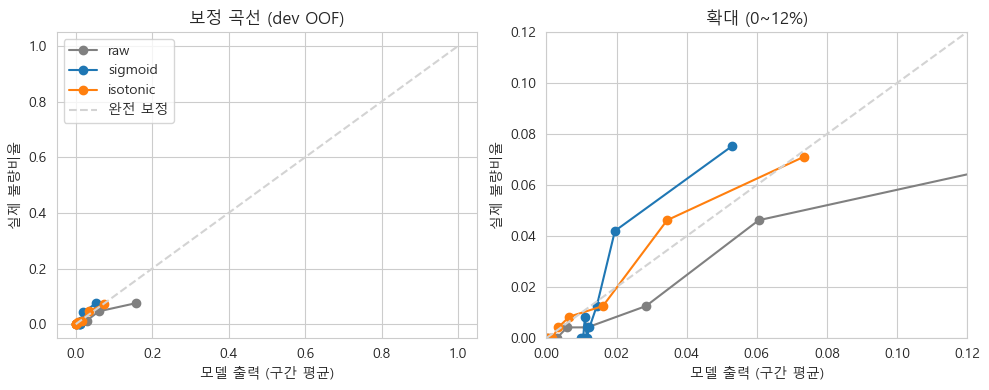

In [41]:
from sklearn.calibration import calibration_curve

oof = pd.read_csv(OUT_DIR / "oof_dev.csv")   # 최종모델 dev OOF (3장·4장에서 사용)
cal = pd.read_csv(OUT_DIR / "calibration_cv.csv")
cal_tbl = cal.groupby("method")[["Brier", "PR_AUC", "Recall@20%", "mean_pred"]].agg(["mean", "std"])
cal_tbl[("실제 불량률", "")] = cal.groupby("method")["obs_rate"].mean()
display(cal_tbl.loc[["raw", "sigmoid", "isotonic"]].round(4))

cal_oof = pd.read_csv(OUT_DIR / "calibration_oof.csv")
CAL_METHOD = json.loads((OUT_DIR / "test_metrics.json").read_text(encoding="utf-8"))["calibration"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for m, col in [("raw", "gray"), ("sigmoid", "C0"), ("isotonic", "C1")]:
    frac, mean_p = calibration_curve(cal_oof[TARGET], cal_oof[f"prob_{m}"], n_bins=8, strategy="quantile")
    ax[0].plot(mean_p, frac, "o-", c=col, label=m)
    ax[1].plot(mean_p, frac, "o-", c=col, label=m)
for a in ax:
    a.plot([0, 1], [0, 1], "--", c="lightgray", label="완전 보정"); a.set_xlabel("모델 출력 (구간 평균)"); a.set_ylabel("실제 불량비율")
ax[0].set_title("보정 곡선 (dev OOF)"); ax[0].legend()
ax[1].set_xlim(0, 0.12); ax[1].set_ylim(0, 0.12); ax[1].set_title("확대 (0~12%)")
plt.tight_layout(); plt.show()

In [42]:
b = cal.groupby("method")[["Brier", "PR_AUC", "Recall@20%", "mean_pred"]].mean()
display(Markdown(f"""보정 전 평균 점수는 {b.loc['raw','mean_pred']:.3f} 로 실제 불량률({cal.obs_rate.mean():.3f})과 다르다. 클래스 가중치로 학습해 점수 척도가 확률과 맞지 않기 때문이다.
Brier 는 raw {b.loc['raw','Brier']:.4f}, sigmoid {b.loc['sigmoid','Brier']:.4f}, isotonic {b.loc['isotonic','Brier']:.4f} 이고, PR-AUC 는 raw {b.loc['raw','PR_AUC']:.3f}, sigmoid {b.loc['sigmoid','PR_AUC']:.3f}, isotonic {b.loc['isotonic','PR_AUC']:.3f} 로 보정 과정에서 순위 성능이 {'떨어졌다' if b.loc[CAL_METHOD,'PR_AUC'] < b.loc['raw','PR_AUC'] else '유지됐다'} (내부 CV 로 학습 데이터가 줄어든 영향).

검사 순위는 보정 전 위험점수로 매기고, 현장에 보여 줄 수치와 위험등급은 Brier 가 가장 낮은 {CAL_METHOD} 보정 확률을 쓴다. 보정 확률도 불량 34건으로 추정한 값이라 운영 중 무작위 표본 검사(4-4)로 계속 확인해야 한다."""))

보정 전 평균 점수는 0.034 로 실제 불량률(0.018)과 다르다. 클래스 가중치로 학습해 점수 척도가 확률과 맞지 않기 때문이다.
Brier 는 raw 0.0186, sigmoid 0.0173, isotonic 0.0173 이고, PR-AUC 는 raw 0.121, sigmoid 0.117, isotonic 0.085 로 보정 과정에서 순위 성능이 떨어졌다 (내부 CV 로 학습 데이터가 줄어든 영향).

검사 순위는 보정 전 위험점수로 매기고, 현장에 보여 줄 수치와 위험등급은 Brier 가 가장 낮은 sigmoid 보정 확률을 쓴다. 보정 확률도 불량 34건으로 추정한 값이라 운영 중 무작위 표본 검사(4-4)로 계속 확인해야 한다.

### 2-3. 행 단위 CV 와 사출 그룹 CV 비교 (부가 실험)
같은 사출 그룹의 두 제품은 공정값이 같다. 행 단위로 나누면 짝이 학습과 평가에 갈라져 성능이 부풀 수 있어, 같은 모델·같은 반복에서 두 방식을 비교한다.

mean         std          over
scheme       group   row group   row 과대평가(%)
model                                       
ExtraTrees   0.121 0.184  0.11 0.105      52
LR_baseline  0.082 0.132 0.056 0.087    61.3
RandomForest 0.103  0.14 0.072 0.075      35

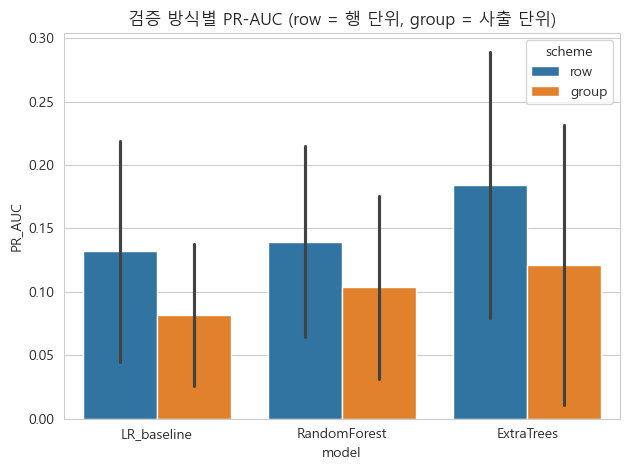

In [43]:
if has_extra("leakage_cv.csv"):
    lk = pd.read_csv(OUT_DIR / "leakage_cv.csv")
    tbl = lk.groupby(["model", "scheme"])["PR_AUC"].agg(["mean", "std"]).unstack("scheme")
    tbl[("over", "과대평가(%)")] = ((tbl[("mean", "row")] / tbl[("mean", "group")] - 1) * 100).round(1)
    display(tbl.round(3))

    ax = sns.barplot(data=lk, x="model", y="PR_AUC", hue="scheme", hue_order=["row", "group"], errorbar="sd")
    ax.set_title("검증 방식별 PR-AUC (row = 행 단위, group = 사출 단위)")
    plt.tight_layout(); plt.show()

In [44]:
if has_extra("leakage_cv.csv"):
    over = tbl[("over", "과대평가(%)")]
    display(Markdown(f"""행 단위 CV 의 PR-AUC 는 사출 그룹 CV 보다 {over.min():+.0f}~{over.max():+.0f}% 높다 ({", ".join(f"{m} {v:+.0f}%" for m, v in over.items())}). 같은 그룹의 짝이 학습에 들어간 효과로 본다.
    모든 비교와 선정은 사출 그룹 CV 로 했고, 행 단위로 검증한 선행연구 수치와는 직접 비교하지 않는다."""))

행 단위 CV 의 PR-AUC 는 사출 그룹 CV 보다 +35~+61% 높다 (ExtraTrees +52%, LR_baseline +61%, RandomForest +35%). 같은 그룹의 짝이 학습에 들어간 효과로 본다.
모든 비교와 선정은 사출 그룹 CV 로 했고, 행 단위로 검증한 선행연구 수치와는 직접 비교하지 않는다.

### 2-4. 오토인코더 비교 (부가 실험)
학습 fold 의 양품만으로 오토인코더를 학습하고 복원 오차를 위험점수로 쓴다. 지도학습 모델과 같은 fold 에서 평가한다.

In [45]:
if has_extra("autoencoder_cv.csv"):
    ae = pd.read_csv(OUT_DIR / "autoencoder_cv.csv")
    sup = cv[(cv.features == "process+cavity")].pivot_table(index=["model", "repeat", "fold"], columns="scope",
                                                              values="PR_AUC").reset_index()
    comp = pd.concat([
        sup.groupby("model")[["all", "cn7", "rg3"]].mean(),
        ae[["PR_AUC_all", "PR_AUC_cn7", "PR_AUC_rg3"]].mean().set_axis(["all", "cn7", "rg3"]).to_frame("AutoEncoder (비지도)").T,
    ])
    comp.loc["무작위 기준"] = [df[TARGET].mean(), df.loc[df["product"] == "cn7", TARGET].mean(),
                              df.loc[df["product"] == "rg3", TARGET].mean()]
    display(comp.round(3).rename(columns={"all": "PR-AUC 전체", "cn7": "CN7", "rg3": "RG3"}))

,PR-AUC 전체,CN7,RG3
CatBoost,0.118,0.227,0.114
ExtraTrees,0.121,0.258,0.083
LR_baseline,0.082,0.226,0.06
LightGBM,0.101,0.179,0.107
RF+ET_ensemble,0.119,0.254,0.091
RandomForest,0.103,0.222,0.098
XGBoost,0.079,0.208,0.067
AutoEncoder (비지도),0.114,0.244,0.029
무작위 기준,0.018,0.014,0.021


In [46]:
if has_extra("autoencoder_cv.csv"):
    display(Markdown(f"""양품만 학습한 오토인코더의 PR-AUC 는 {comp.loc['AutoEncoder (비지도)','all']:.3f} 로 무작위({comp.loc['무작위 기준','all']:.3f})보다 높지만 지도학습 최고값({comp.drop(['AutoEncoder (비지도)','무작위 기준'])['all'].max():.3f})보다 낮다.
    라벨이 있는 이 과제에는 지도학습을 쓰고, 오토인코더는 라벨이 부족한 신규 제품에서의 대안으로 남긴다."""))

양품만 학습한 오토인코더의 PR-AUC 는 0.114 로 무작위(0.018)보다 높지만 지도학습 최고값(0.121)보다 낮다.
라벨이 있는 이 과제에는 지도학습을 쓰고, 오토인코더는 라벨이 부족한 신규 제품에서의 대안으로 남긴다.

### 2-5. 최종모델 대비 유의성 검정
최종모델과 나머지 13개 조합을 같은 fold 끼리 짝지어 비교한다.
- wins / losses: 25개 fold 중 최종모델이 이긴 / 진 횟수
- Wilcoxon 부호순위 검정: fold 들이 독립이 아니어서 다소 낙관적
- Nadeau-Bengio 보정 t-검정: 반복 k-fold 의 학습 데이터 겹침을 보정한 검정. Holm 보정 p 도 함께 본다.

In [47]:
sig = pd.read_csv(OUT_DIR / "significance.csv")
print("최종모델:", BEST_MODEL, "/", BEST_FS)
for met in ["PR_AUC", "Recall@20%"]:
    print(f"\n■ {met}")
    display(sig[sig.metric == met][["compared_model", "features", "best_mean", "other_mean", "mean_diff",
                                     "wins", "losses", "wilcoxon_p", "corrected_t_p"]].round(3))

최종모델: ExtraTrees / process+cavity

■ PR_AUC


,compared_model,features,best_mean,other_mean,mean_diff,wins,losses,wilcoxon_p,corrected_t_p
0,RF+ET_ensemble,process+cavity,0.121,0.119,0.002,15,10,0.895,0.872
1,CatBoost,process+cavity,0.121,0.118,0.003,14,11,0.791,0.944
2,RandomForest,process+cavity,0.121,0.103,0.018,17,8,0.312,0.695
3,LightGBM,process+cavity,0.121,0.101,0.021,15,10,0.525,0.723
4,RF+ET_ensemble,process_only,0.121,0.092,0.03,25,0,0,0
5,ExtraTrees,process_only,0.121,0.088,0.033,25,0,0,0.001
6,LR_baseline,process+cavity,0.121,0.082,0.04,20,5,0,0.316
7,XGBoost,process+cavity,0.121,0.079,0.043,18,7,0.015,0.433
8,CatBoost,process_only,0.121,0.071,0.05,23,2,0,0.299
9,LightGBM,process_only,0.121,0.071,0.051,20,5,0.001,0.381



■ Recall@20%


,compared_model,features,best_mean,other_mean,mean_diff,wins,losses,wilcoxon_p,corrected_t_p
13,RF+ET_ensemble,process+cavity,0.7,0.694,0.006,5,3,0.779,0.903
14,CatBoost,process+cavity,0.7,0.663,0.037,9,5,0.232,0.644
15,LightGBM,process+cavity,0.7,0.643,0.057,9,3,0.053,0.461
16,RandomForest,process+cavity,0.7,0.589,0.111,14,2,0.002,0.161
17,XGBoost,process+cavity,0.7,0.551,0.149,17,2,0.002,0.193
18,LR_baseline,process+cavity,0.7,0.53,0.169,16,3,0.002,0.184
19,ExtraTrees,process_only,0.7,0.489,0.21,21,1,0,0.027
20,RF+ET_ensemble,process_only,0.7,0.465,0.235,18,0,0,0.028
21,RandomForest,process_only,0.7,0.431,0.269,22,0,0,0.01
22,LightGBM,process_only,0.7,0.415,0.285,18,0,0,0.041


In [48]:
sp = sig[sig.metric == "PR_AUC"].sort_values("corrected_t_p", ascending=False)
sr = sig[sig.metric == "Recall@20%"]
n_sig = int((sr.corrected_t_p < 0.05).sum())
display(Markdown(f"""PR-AUC 에서 최종모델과 가장 가까운 조합은 {", ".join(f"{r.compared_model}/{r.features}(p={r.corrected_t_p:.2f})" for r in sp.head(3).itertuples())} 로, 상위권은 통계적으로 구분되지 않는다.
Recall@20% 에서는 13개 비교 중 {n_sig}개가 보정 t p<0.05 이지만 Holm 보정 후에는 {int((sr.corrected_t_p_holm < 0.05).sum())}개다."""))

PR-AUC 에서 최종모델과 가장 가까운 조합은 CatBoost/process+cavity(p=0.94), RF+ET_ensemble/process+cavity(p=0.87), LightGBM/process+cavity(p=0.72) 로, 상위권은 통계적으로 구분되지 않는다.
Recall@20% 에서는 13개 비교 중 7개가 보정 t p<0.05 이지만 Holm 보정 후에는 0개다.

### 2-6. 불균형 처리 방식 비교 (부가 실험)
최종모델 구조에서 불균형 처리만 바꿔 같은 fold 에서 비교한다. 오버샘플링은 학습 fold 에만 적용한다.
클래스 가중치는 선정 전에 정한 설계값이라 선정 후보에 넣지 않았고, 여기서는 민감도만 확인한다.

PR_AUC_all       PR_AUC_cn7       PR_AUC_rg3       Recall@20%      
                      mean   std       mean   std       mean   std       mean   std
method                                                                             
가중치 없음               0.127  0.11      0.276 0.239      0.095 0.067      0.717  0.19
클래스 가중치 (현재)         0.121  0.11      0.258 0.236      0.083 0.039        0.7 0.195
BorderlineSMOTE      0.107 0.099      0.227 0.191      0.076 0.045      0.636  0.22
ADASYN               0.104 0.057      0.216 0.128      0.091 0.047      0.722 0.194
SMOTE-NC             0.101 0.055      0.212 0.123      0.088 0.052      0.723 0.194

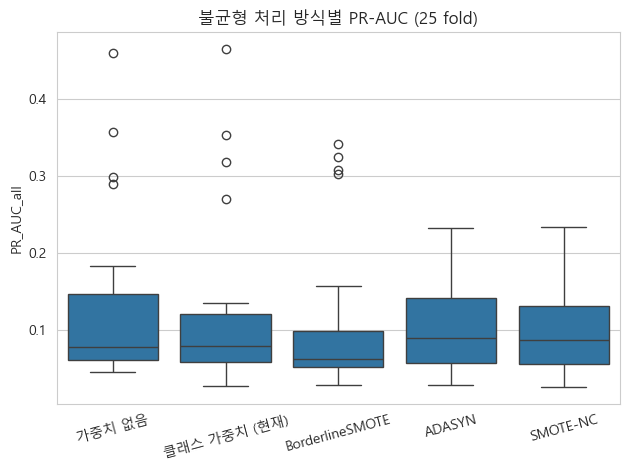

In [49]:
if has_extra("imbalance_cv.csv"):
    imb = pd.read_csv(OUT_DIR / "imbalance_cv.csv")
    cols = ["PR_AUC_all", "PR_AUC_cn7", "PR_AUC_rg3", "Recall@20%"]
    tbl = imb.groupby("method")[cols].agg(["mean", "std"]).round(3)
    display(tbl.sort_values(("PR_AUC_all", "mean"), ascending=False))

    ax = sns.boxplot(data=imb, x="method", y="PR_AUC_all", order=tbl.sort_values(("PR_AUC_all", "mean"), ascending=False).index)
    ax.set_title("불균형 처리 방식별 PR-AUC (25 fold)"); ax.set_xlabel("")
    plt.xticks(rotation=15); plt.tight_layout(); plt.show()

In [50]:
if has_extra("imbalance_cv.csv"):
    from src.experiments import corrected_t
    im = imb.groupby("method")[["PR_AUC_all", "Recall@20%"]].mean()
    cur, nw = im.loc["클래스 가중치 (현재)"], im.loc["가중치 없음"]
    pw = imb.pivot_table(index=["repeat", "fold"], columns="method", values=["PR_AUC_all", "Recall@20%"])
    p_pr = corrected_t(pw[("PR_AUC_all", "가중치 없음")] - pw[("PR_AUC_all", "클래스 가중치 (현재)")])
    p_rc = corrected_t(pw[("Recall@20%", "가중치 없음")] - pw[("Recall@20%", "클래스 가중치 (현재)")])
    display(Markdown(f"""PR-AUC 는 가중치 없음 {nw.PR_AUC_all:.3f}, 클래스 가중치 {cur.PR_AUC_all:.3f} (보정 t p={p_pr:.2f}), Recall@20% 는 {nw['Recall@20%']:.3f}, {cur['Recall@20%']:.3f} (p={p_rc:.2f}) 로 두 지표 모두 차이가 유의하지 않다. SMOTE 계열 PR-AUC 는 {", ".join(f"{m} {v:.3f}" for m, v in im.PR_AUC_all.drop(['클래스 가중치 (현재)','가중치 없음']).items())} 로 더 낮다.
    클래스 가중치는 설계값대로 유지했다. 이 비교는 최종모델 구조에서만 했으므로 다른 모델의 가중치 효과는 확인하지 않았다. 오버샘플링은 충돌 불량을 복제·보간할 뿐이어서 효과가 없었던 것으로 본다."""))

PR-AUC 는 가중치 없음 0.127, 클래스 가중치 0.121 (보정 t p=0.66), Recall@20% 는 0.717, 0.700 (p=0.80) 로 두 지표 모두 차이가 유의하지 않다. SMOTE 계열 PR-AUC 는 ADASYN 0.104, BorderlineSMOTE 0.107, SMOTE-NC 0.101 로 더 낮다.
클래스 가중치는 설계값대로 유지했다. 이 비교는 최종모델 구조에서만 했으므로 다른 모델의 가중치 효과는 확인하지 않았다. 오버샘플링은 충돌 불량을 복제·보간할 뿐이어서 효과가 없었던 것으로 본다.

### 2-7. 스태킹 앙상블과 MLP (부가 실험)
- 스태킹: ExtraTrees, RandomForest, XGBoost, LR 의 예측을 로지스틱 회귀로 조합. 메타 학습용 내부 CV 도 사출 그룹 단위.
- MLP: 은닉층 32-16, 64-32-16. class_weight 가 없어 학습 fold 안에서만 불량을 무작위 복제한다.
- CNN, LSTM 은 사출당 요약 공정값 24개인 표 데이터에 맞지 않아 쓰지 않았다.

,PR_AUC_all,ROC_AUC,Recall@20%,PR_AUC_cn7,PR_AUC_rg3,최종모델 대비 승/패
model,,,,,,
최종모델,0.121,0.845,0.7,0.258,0.083,-
MLP 32-16,0.064,0.734,0.493,0.177,0.062,4/21
MLP 64-32-16,0.062,0.693,0.512,0.172,0.048,1/24
스태킹 (ET·RF·XGB·LR → LR),0.109,0.805,0.598,0.259,0.098,9/16


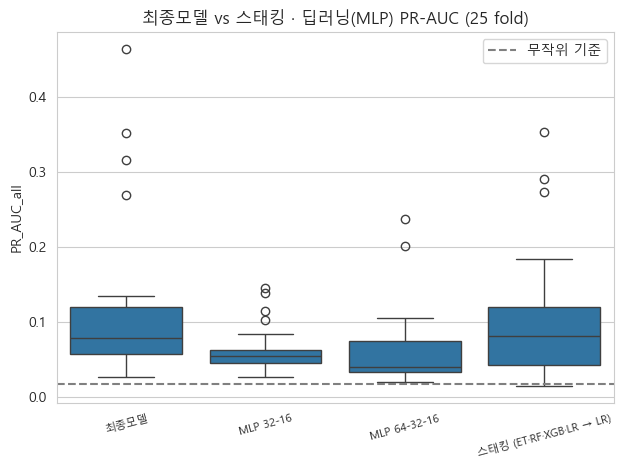

In [51]:
if has_extra("dl_stacking_cv.csv"):
    dl = pd.read_csv(OUT_DIR / "dl_stacking_cv.csv")
    cols = ["PR_AUC_all", "ROC_AUC", "Recall@20%", "PR_AUC_cn7", "PR_AUC_rg3"]
    tbl = dl.groupby("model", sort=False)[cols].mean()
    ref = dl[dl.model == "최종모델"].set_index(["repeat", "fold"])["PR_AUC_all"]
    tbl["최종모델 대비 승/패"] = [
        "-" if m == "최종모델" else
        f"{int((d.set_index(['repeat', 'fold'])['PR_AUC_all'] > ref).sum())}/{int((d.set_index(['repeat', 'fold'])['PR_AUC_all'] < ref).sum())}"
        for m, d in dl.groupby("model", sort=False)]
    display(tbl.round(3))

    ax = sns.boxplot(data=dl, x="model", y="PR_AUC_all")
    ax.axhline(df[TARGET].mean(), ls="--", c="gray", label="무작위 기준")
    ax.set_title("최종모델 vs 스태킹 · 딥러닝(MLP) PR-AUC (25 fold)"); ax.set_xlabel(""); ax.legend()
    plt.xticks(rotation=15, fontsize=8); plt.tight_layout(); plt.show()

In [52]:
if has_extra("dl_stacking_cv.csv"):
    t = tbl["PR_AUC_all"]
    display(Markdown(f"""최종모델 {t['최종모델']:.3f} 에 비해 스태킹은 {t.filter(like='스태킹').iloc[0]:.3f}, MLP 는 최고 {t.filter(like='MLP').max():.3f} 로 더 복잡한 모델이 성능을 올리지 못했다. 불량이 수십 건인 데이터에서는 메타 모델이나 신경망이 더 배울 정보가 부족하다."""))

최종모델 0.121 에 비해 스태킹은 0.109, MLP 는 최고 0.064 로 더 복잡한 모델이 성능을 올리지 못했다. 불량이 수십 건인 데이터에서는 메타 모델이나 신경망이 더 배울 정보가 부족하다.

### 2-8. 시간 검증: 생산순번 블록 CV(②)와 과거→미래 대리 검증(③)
CN7 불량은 생산 초반 한 구간에 몰려 있어, ① 의 결과는 같은 시기 이웃 사출 덕분에 낙관적일 수 있다.
- ② 생산순번 블록 CV: 연속 구간(사출 그룹 단위 경계)을 통째로 평가에서 뺀다.
- ③ 과거→미래 대리 검증: 앞 구간으로만 학습해 다음 구간을 평가한다.

불량이 없어 평가할 수 없는 구간은 빼지 않고 사유와 함께 표시한다.

In [53]:
if has_extra("time_block_cv.csv"):
    tb_all = pd.read_csv(OUT_DIR / "time_block_cv.csv")
    skipped = tb_all[tb_all.model == "-"]
    print(f"평가 불가 fold: {len(skipped)}개", skipped[["n_blocks", "repeat", "fold", "n_fail_train", "n_fail_eval", "note"]].to_dict("records"))
    tb = tb_all[tb_all.model != "-"]
    cols = ["PR_AUC_all", "PR_AUC_cn7", "PR_AUC_rg3", "ROC_AUC", "Recall@20%"]
    shot = cv[(cv.model == BEST_MODEL) & (cv.features == BEST_FS)].pivot_table(
        index=["repeat", "fold"], columns="scope", values=["PR_AUC", "ROC_AUC", "Recall@20%"])
    scen = pd.DataFrame({
        "① 무작위 사출 그룹 CV": [shot[("PR_AUC", "all")].mean(), shot[("PR_AUC", "cn7")].mean(), shot[("PR_AUC", "rg3")].mean(),
                              shot[("ROC_AUC", "all")].mean(), shot[("Recall@20%", "all")].mean()],
        **{f"② 생산순번 블록 {nb}개": tb[(tb.model == BEST_MODEL) & (tb.features == BEST_FS) & (tb.n_blocks == nb)][cols].mean().values
           for nb in sorted(tb.n_blocks.unique())}}, index=cols)
    display(na(scen))
    print("■ 블록 CV 평가 fold 의 제품별 불량 수")
    display(tb[(tb.model == BEST_MODEL) & (tb.features == BEST_FS)][["n_blocks", "repeat", "fold", "n_fail_eval_cn7", "n_fail_eval_rg3", "PR_AUC_cn7", "PR_AUC_rg3"]].pipe(na))
    rank = tb.groupby(["n_blocks", "features", "model"])[cols].mean().round(3)
    display(rank.sort_values(["n_blocks", "PR_AUC_all"], ascending=[True, False]))

평가 불가 fold: 0개 []


,① 무작위 사출 그룹 CV,② 생산순번 블록 8개,② 생산순번 블록 16개
PR_AUC_all,0.121,0.045,0.06
PR_AUC_cn7,0.258,0.215,0.173
PR_AUC_rg3,0.083,0.063,0.071
ROC_AUC,0.845,0.729,0.802
Recall@20%,0.7,0.42,0.579


■ 블록 CV 평가 fold 의 제품별 불량 수


,n_blocks,repeat,fold,n_fail_eval_cn7,n_fail_eval_rg3,PR_AUC_cn7,PR_AUC_rg3
2,8,0,0,0,6,N/A,0.05
10,8,0,1,13,2,0.07,0.045
18,8,0,2,0,7,N/A,0.026
26,8,0,3,0,6,N/A,0.081
34,8,1,0,0,4,N/A,0.023
42,8,1,1,13,12,0.398,0.049
50,8,1,2,0,3,N/A,0.126
58,8,1,3,0,2,N/A,0.055
66,8,2,0,0,3,N/A,0.117
74,8,2,1,0,11,N/A,0.097


PR_AUC_all  PR_AUC_cn7  PR_AUC_rg3  ROC_AUC  Recall@20%
n_blocks features       model                                                                  
8        process+cavity RandomForest          0.06       0.169       0.073     0.62       0.291
                        CatBoost             0.049       0.235       0.062     0.71       0.491
                        LR_baseline          0.048       0.154       0.052    0.709       0.453
                        ExtraTrees           0.045       0.215       0.063    0.729        0.42
                        RF+ET_ensemble       0.045       0.189       0.078    0.693       0.379
                        LightGBM             0.038       0.206       0.057    0.643       0.274
                        XGBoost              0.038       0.186       0.053    0.627       0.304
         process_only   ExtraTrees           0.034       0.339       0.041    0.643       0.383
16       process+cavity CatBoost             0.077       0.203       0.095    0.788       0.558
                        ExtraTrees            0.06       0.173       0.071    0.802       0.579
                        RF+ET_ensemble        0.06       0.151       0.071    0.782       0.496
                        RandomForest          0.06       0.119       0.073     0.73       0.465
                        LightGBM             0.052       0.094       0.071    0.745       0.452
                        LR_baseline          0.051       0.056       0.068    0.709        0.46
                        XGBoost              0.051       0.071       0.078    0.716       0.425
         process_only   ExtraTrees           0.039        0.14       0.044    0.702       0.375

In [54]:
if EXTRA["time_block_cv.csv"]:
    sc = scen.loc["PR_AUC_all"]
    display(Markdown(f"""같은 모델의 PR-AUC 는 ① 무작위 사출 그룹 CV {sc.iloc[0]:.3f}, ② 생산순번 블록 CV {", ".join(f"{v:.3f}" for v in sc.iloc[1:])} 이다.
    CN7 불량이 한 시기에 몰려 있어 그 시기의 사출을 학습에서 빼면 성능이 크게 낮아진다. ① 은 같은 기간 안의 검사 결과로 학습한 경우의 낙관적인 값이고, ② 는 평가 구간 뒤의 데이터도 학습에 쓰므로 운영 성능 자체는 아니다."""))

같은 모델의 PR-AUC 는 ① 무작위 사출 그룹 CV 0.121, ② 생산순번 블록 CV 0.045, 0.060 이다.
CN7 불량이 한 시기에 몰려 있어 그 시기의 사출을 학습에서 빼면 성능이 크게 낮아진다. ① 은 같은 기간 안의 검사 결과로 학습한 경우의 낙관적인 값이고, ② 는 평가 구간 뒤의 데이터도 학습에 쓰므로 운영 성능 자체는 아니다.

In [55]:
fwd = pd.read_csv(OUT_DIR / "forward_cv.csv")
show = ["features", "평가 구간", "학습 구간", "scope", "평가 행 수", "평가 사출 수", "평가 불량 수", "학습 불량 수",
        "PR_AUC", "무작위 PR_AUC", "ROC_AUC", "Recall@20%", "상위20% 검사 시 오경보 수", "사유"]
display(na(fwd[[c for c in show if c in fwd.columns]]))

,features,평가 구간,학습 구간,scope,평가 행 수,평가 사출 수,평가 불량 수,학습 불량 수,PR_AUC,무작위 PR_AUC,ROC_AUC,Recall@20%,상위20% 검사 시 오경보 수,사유
0,process+cavity,1,0~0,all,380,190,8,17,0.036,0.021,0.649,0.25,N/A,N/A
1,process+cavity,1,0~0,cn7,192,96,0,13,N/A,N/A,N/A,N/A,39,평가 구간 불량 0건 → PR-AUC·Recall 정의 불가 (N/A)
2,process+cavity,1,0~0,rg3,188,94,8,4,0.061,0.043,0.617,0.125,N/A,N/A
3,process+cavity,2,0~1,all,382,191,3,25,0.055,0.008,0.635,0.667,N/A,N/A
4,process+cavity,2,0~1,cn7,194,97,0,13,N/A,N/A,N/A,N/A,39,평가 구간 불량 0건 → PR-AUC·Recall 정의 불가 (N/A)
5,process+cavity,2,0~1,rg3,188,94,3,12,0.063,0.016,0.598,0.333,N/A,N/A
6,process+cavity,3,0~2,all,380,190,3,28,0.05,0.008,0.889,0.667,N/A,N/A
7,process+cavity,3,0~2,cn7,192,96,0,13,N/A,N/A,N/A,N/A,39,평가 구간 불량 0건 → PR-AUC·Recall 정의 불가 (N/A)
8,process+cavity,3,0~2,rg3,188,94,3,15,0.05,0.016,0.773,0.667,N/A,N/A
9,process+cavity,4,0~3,all,384,192,3,31,0.022,0.008,0.731,0.333,N/A,N/A


In [56]:
fb = fwd[fwd.features == BEST_FS]
ok = fb[fb["사유"].fillna("") == ""]
rg = ok[ok.scope == "rg3"]
cn_na = fb[(fb.scope == "cn7") & (fb["사유"].fillna("") != "")]
display(Markdown(f"""과거→미래 검증에서 CN7 은 {len(cn_na)}개 평가 구간 모두 불량이 없어 PR-AUC 와 Recall 을 계산할 수 없다(N/A). 개발셋의 CN7 불량이 모두 첫 구간에 있기 때문이며, 대신 상위 20% 검사 시 생기는 오경보 수를 기록했다.
RG3 는 {len(rg)}개 구간에서 PR-AUC {rg.PR_AUC.min():.3f}~{rg.PR_AUC.max():.3f}(무작위 {rg['무작위 PR_AUC'].min():.3f}~{rg['무작위 PR_AUC'].max():.3f}), Recall@20% {rg['Recall@20%'].min():.2f}~{rg['Recall@20%'].max():.2f} 이며, 구간당 불량이 {int(rg['평가 불량 수'].min())}~{int(rg['평가 불량 수'].max())}건이라 값이 크게 흔들린다.

이 데이터로는 CN7 불안정 구간을 미리 예측할 수 있는지 검증할 수 없다. 성능은 ① 을 상한, ②·③ 을 보수적 범위로 함께 제시한다. 불안정 구간이 여러 번 포함된 더 긴 기간의 데이터가 있어야 확정할 수 있고, 그 전까지 처음 보는 불안정 구간은 가동 초기 강화검사와 공정 흔들림 경보(4-3)로 대응한다."""))

과거→미래 검증에서 CN7 은 4개 평가 구간 모두 불량이 없어 PR-AUC 와 Recall 을 계산할 수 없다(N/A). 개발셋의 CN7 불량이 모두 첫 구간에 있기 때문이며, 대신 상위 20% 검사 시 생기는 오경보 수를 기록했다.
RG3 는 4개 구간에서 PR-AUC 0.026~0.063(무작위 0.016~0.043), Recall@20% 0.12~0.67 이며, 구간당 불량이 3~8건이라 값이 크게 흔들린다.

이 데이터로는 CN7 불안정 구간을 미리 예측할 수 있는지 검증할 수 없다. 성능은 ① 을 상한, ②·③ 을 보수적 범위로 함께 제시한다. 불안정 구간이 여러 번 포함된 더 긴 기간의 데이터가 있어야 확정할 수 있고, 그 전까지 처음 보는 불안정 구간은 가동 초기 강화검사와 공정 흔들림 경보(4-3)로 대응한다.

### 2-9. 최종모델 선정 근거
목적은 양/불 판정이 아니라 한정된 검사 용량을 어디에 먼저 쓸지 정하는 것이다. 그래서 검사량을 고정한 포착률(Recall@k%)과
모든 검사량에서의 순위 품질(PR-AUC)을 본다. 결과를 본 뒤 기준을 고르지 않도록 분석 전에 PR-AUC 를 선정 기준, Recall@20% 를 보조 지표로 정했다.

반복 CV 의 fold 는 서로 독립이 아니고, 13개 조합을 동시에 비교하며, 1위를 먼저 고른 뒤 비교하므로 1위의 우위는 과대평가되기 쉽다.
작은 평균 차이는 우열로 해석하지 않는다.

In [57]:
MC = ["PR_AUC", "ROC_AUC", "F1", "Recall@20%", "Precision@20%", "F1@20%"]
g = cv[cv.scope == "all"].groupby(["model", "features"])
sel = g[MC].mean().join(g[["PR_AUC", "Recall@20%"]].std().add_suffix(" 표준편차"))
for met, lab in [("PR_AUC", "PR-AUC"), ("Recall@20%", "Recall@20%")]:
    s_ = sig[sig.metric == met].set_index(["compared_model", "features"])
    sel[f"{lab} 보정t p"] = s_["corrected_t_p"].reindex(sel.index)
    sel[f"{lab} Holm p"] = s_["corrected_t_p_holm"].reindex(sel.index)
sel = sel.sort_values("PR_AUC", ascending=False)
sel["PR-AUC 순위"] = range(1, len(sel) + 1)
sel["Recall@20% 순위"] = sel["Recall@20%"].rank(ascending=False, method="min").astype(int)
sel["F1 순위"] = sel["F1"].rank(ascending=False, method="min").astype(int)
display(sel.round(3).astype(object).where(sel.notna(), "-"))   # p 값의 "-" = 최종모델 자신

,,PR_AUC,ROC_AUC,F1,Recall@20%,Precision@20%,F1@20%,PR_AUC 표준편차,Recall@20% 표준편차,PR-AUC 보정t p,PR-AUC Holm p,Recall@20% 보정t p,Recall@20% Holm p,PR-AUC 순위,Recall@20% 순위,F1 순위
model,features,,,,,,,,,,,,,,,
ExtraTrees,process+cavity,0.121,0.845,0.057,0.7,0.061,0.11,0.11,0.195,-,-,-,-,1,1,9
RF+ET_ensemble,process+cavity,0.119,0.84,0.072,0.694,0.059,0.107,0.1,0.209,0.872,1,0.903,1,2,2,5
CatBoost,process+cavity,0.118,0.831,0.113,0.663,0.057,0.104,0.075,0.186,0.944,1,0.644,1,3,3,1
RandomForest,process+cavity,0.103,0.807,0.095,0.589,0.051,0.093,0.072,0.2,0.695,1,0.161,0.967,4,5,2
LightGBM,process+cavity,0.101,0.816,0.084,0.643,0.055,0.101,0.069,0.183,0.723,1,0.461,1,5,4,4
RF+ET_ensemble,process_only,0.092,0.759,0.036,0.465,0.04,0.072,0.107,0.199,0,0.006,0.028,0.271,6,9,12
ExtraTrees,process_only,0.088,0.759,0.024,0.489,0.041,0.075,0.108,0.176,0.001,0.011,0.027,0.271,7,8,14
LR_baseline,process+cavity,0.082,0.77,0.061,0.53,0.046,0.084,0.056,0.263,0.316,1,0.184,0.967,8,7,8
XGBoost,process+cavity,0.079,0.784,0.095,0.551,0.05,0.091,0.051,0.215,0.433,1,0.193,0.967,9,6,3


In [58]:
b = sel.loc[(BEST_MODEL, BEST_FS)]
f1_low = sel["F1"].idxmin()
n_rc_sig = int((sel["Recall@20% Holm p"] < 0.05).sum())
display(Markdown(f"""- {BEST_MODEL}/{BEST_FS} 는 PR-AUC {b.PR_AUC:.3f} 로 규칙상 1위지만, 2~4위({", ".join(f"{m}/{f}" for m, f in sel.index[1:4])})와의 보정 t p 값이 {", ".join(f"{v:.2f}" for v in sel["PR-AUC 보정t p"].iloc[1:4])} 로 구분되지 않는다. fold 간 표준편차({b['PR_AUC 표준편차']:.3f})가 평균 차이보다 크다.
- Recall@20% 는 {b['Recall@20%']:.3f}({int(b['Recall@20% 순위'])}위)이고 Holm 보정 후 유의하게 앞서는 조합은 {n_rc_sig}/{int(sel['Recall@20% Holm p'].notna().sum())}개다. 운영점 F1@20% {b['F1@20%']:.3f}, Precision@20% {b['Precision@20%']:.3f}.
- 임계값 F1 은 {b.F1:.3f} 로 {len(sel)}개 중 {int(b['F1 순위'])}위다(최저 {f1_low[0]}/{f1_low[1]} {sel.F1.min():.3f}). fold 임계값이 흔들리기 때문이며(2-1-1), 그래서 임계값 F1 은 선정에 쓰지 않는다. 검사량을 고정한 F1@20% 에서는 {b['F1@20%']:.3f} 로 {int(sel['F1@20%'].rank(ascending=False, method='min')[(BEST_MODEL, BEST_FS)])}위다.

규칙대로 {BEST_MODEL}/{BEST_FS} 를 최종모델로 쓰되, 상위권 모델들과 비슷한 수준으로 본다. PR-AUC 상위 4개 조합의 Recall@20% 가 {sel['Recall@20%'].iloc[:4].min():.3f}~{sel['Recall@20%'].iloc[:4].max():.3f} 여서 어느 조합을 택해도 운영상 결론은 크게 달라지지 않는다."""))

- ExtraTrees/process+cavity 는 PR-AUC 0.121 로 규칙상 1위지만, 2~4위(RF+ET_ensemble/process+cavity, CatBoost/process+cavity, RandomForest/process+cavity)와의 보정 t p 값이 0.87, 0.94, 0.70 로 구분되지 않는다. fold 간 표준편차(0.110)가 평균 차이보다 크다.
- Recall@20% 는 0.700(1위)이고 Holm 보정 후 유의하게 앞서는 조합은 0/13개다. 운영점 F1@20% 0.110, Precision@20% 0.061.
- 임계값 F1 은 0.057 로 14개 중 9위다(최저 ExtraTrees/process_only 0.024). fold 임계값이 흔들리기 때문이며(2-1-1), 그래서 임계값 F1 은 선정에 쓰지 않는다. 검사량을 고정한 F1@20% 에서는 0.110 로 1위다.

규칙대로 ExtraTrees/process+cavity 를 최종모델로 쓰되, 상위권 모델들과 비슷한 수준으로 본다. PR-AUC 상위 4개 조합의 Recall@20% 가 0.589~0.700 여서 어느 조합을 택해도 운영상 결론은 크게 달라지지 않는다.

### 2-9-1. 통합 모델과 제품별 모델 (부가 실험)
두 제품을 한 모델(제품 구분 변수 포함)로 학습하는 경우와 제품마다 따로 학습하는 경우를 같은 25개 fold 에서 비교한다.
제품별 모델은 학습 불량이 CN7 약 10건, RG3 약 17건이다.

In [59]:
if has_extra("product_model_cv.csv"):
    pm = pd.read_csv(OUT_DIR / "product_model_cv.csv")
    pmt = pm.groupby(["product", "approach"])[["PR_AUC", "Recall@20%", "n_fail_train", "n_fail_eval"]].mean()
    pmt["N/A fold 수"] = pm.groupby(["product", "approach"])["PR_AUC"].apply(lambda s: int(s.isna().sum()))
    display(pmt.round(3))
    from src.experiments import corrected_t
    for pr in ["cn7", "rg3"]:
        w = pm[pm["product"] == pr].pivot_table(index=["repeat", "fold"], columns="approach", values="PR_AUC")
        print(f"{pr.upper()} 제품별 − 통합 PR-AUC 차이 {(w['제품별 모델'] - w['통합 모델']).mean():+.3f}, 보정 t p={corrected_t(w['제품별 모델'] - w['통합 모델']):.2f}")

PR_AUC  Recall@20%  n_fail_train  n_fail_eval  N/A fold 수
product approach                                                           
cn7     제품별 모델     0.266       0.898          10.4          2.6           4
        통합 모델      0.258       0.901          10.4          2.6           4
rg3     제품별 모델     0.081       0.545          16.8          4.2           0
        통합 모델      0.083       0.478          16.8          4.2           0

CN7 제품별 − 통합 PR-AUC 차이 +0.008, 보정 t p=0.81
RG3 제품별 − 통합 PR-AUC 차이 -0.002, 보정 t p=0.88


In [60]:
if has_extra("product_model_cv.csv"):
    pmm = pm.groupby(["product", "approach"])["PR_AUC"].mean().unstack()
    display(Markdown(f"""PR-AUC 는 CN7 통합 {pmm.loc['cn7','통합 모델']:.3f} / 제품별 {pmm.loc['cn7','제품별 모델']:.3f}, RG3 통합 {pmm.loc['rg3','통합 모델']:.3f} / 제품별 {pmm.loc['rg3','제품별 모델']:.3f} 이다.
    {"차이가 작아 관리가 단순한 통합 모델을 쓴다." if (pmm['제품별 모델'] - pmm['통합 모델']).abs().max() < 0.03 else "차이가 있으나 불량 표본이 적어 통합 모델을 유지하고, 데이터가 늘면 다시 비교한다."}"""))

PR-AUC 는 CN7 통합 0.258 / 제품별 0.266, RG3 통합 0.083 / 제품별 0.081 이다.
차이가 작아 관리가 단순한 통합 모델을 쓴다.

### 2-10. 시도한 방법 요약

In [61]:
def _m(f, col, key, by="method"):
    if not EXTRA.get(f, False):
        return "미실행"
    d = pd.read_csv(OUT_DIR / f)
    return f"{d[d[by] == key][col].mean():.3f}" if key in set(d[by]) else "-"

fin = f"{allscope.max():.3f}"
trials = pd.DataFrame([
    ["사출 그룹 CV (vs 행 단위)", "짝 행 누수 방지", f"행 {_m('leakage_cv.csv', 'PR_AUC', 'row', 'scheme')} / 그룹 {_m('leakage_cv.csv', 'PR_AUC', 'group', 'scheme')}", "채택", "행 단위 검증은 성능을 부풀릴 수 있다"],
    ["클래스 가중치 (vs 없음)", "불량 1.8% 불균형", f"가중치 {_m('imbalance_cv.csv', 'PR_AUC_all', '클래스 가중치 (현재)')} / 없음 {_m('imbalance_cv.csv', 'PR_AUC_all', '가중치 없음')}", "유지 (사전 설계)", "차이는 잡음 수준"],
    ["SMOTE-NC·Borderline·ADASYN", "불량 표본 증강", f"SMOTE-NC {_m('imbalance_cv.csv', 'PR_AUC_all', 'SMOTE-NC')}", "미채택", "충돌 불량을 복제할 뿐 정보가 늘지 않음"],
    ["스태킹 (ET·RF·XGB·LR→LR)", "모델 조합", f"{_m('dl_stacking_cv.csv', 'PR_AUC_all', '스태킹 (ET·RF·XGB·LR → LR)', 'model')}", "미채택", "불량 수십 건에서 메타 학습 이득 없음"],
    ["MLP 2종", "표 데이터 딥러닝", f"{_m('dl_stacking_cv.csv', 'PR_AUC_all', 'MLP 64-32-16', 'model')}", "미채택", "표본이 적어 트리 앙상블보다 불안정"],
    ["오토인코더 (양품 학습)", "라벨 없는 이상탐지", (f"{pd.read_csv(OUT_DIR / 'autoencoder_cv.csv')['PR_AUC_all'].mean():.3f}" if EXTRA['autoencoder_cv.csv'] else "미실행"), "미채택 (대안으로 기록)", "라벨 부족 시 대안"],
    ["자기학습 (비라벨 가짜 라벨)", "비라벨 7만 행 활용", f"라벨만 {_m('self_training_cv.csv', 'PR_AUC_all', 'labeled_only')} / 자기학습 {_m('self_training_cv.csv', 'PR_AUC_all', 'self_training_strict')}", "미채택", "분포가 달라 개선을 신뢰할 수 없음"],
    ["확률 보정 (sigmoid·isotonic)", "표시 확률 정확도", f"Brier 최소: {CAL_METHOD}", "표시용만 채택", "순위는 보정 전 점수 유지"],
    ["추정 캐비티 특성", "캐비티0 불량 편중", f"평균 PR-AUC 차이 {dpr.mean():+.3f}", "채택 (대안: process_only)", "추정값 의존 → 운영 확보 필요"],
], columns=["방법", "시도 이유", "검증 결과 (CV PR-AUC 등)", "채택 여부", "배운 점"])
print("최종모델 CV PR-AUC:", fin)
display(trials)

최종모델 CV PR-AUC: 0.121


,방법,시도 이유,검증 결과 (CV PR-AUC 등),채택 여부,배운 점
0,사출 그룹 CV (vs 행 단위),짝 행 누수 방지,행 0.152 / 그룹 0.102,채택,행 단위 검증은 성능을 부풀릴 수 있다
1,클래스 가중치 (vs 없음),불량 1.8% 불균형,가중치 0.121 / 없음 0.127,유지 (사전 설계),차이는 잡음 수준
2,SMOTE-NC·Borderline·ADASYN,불량 표본 증강,SMOTE-NC 0.101,미채택,충돌 불량을 복제할 뿐 정보가 늘지 않음
3,스태킹 (ET·RF·XGB·LR→LR),모델 조합,0.109,미채택,불량 수십 건에서 메타 학습 이득 없음
4,MLP 2종,표 데이터 딥러닝,0.062,미채택,표본이 적어 트리 앙상블보다 불안정
5,오토인코더 (양품 학습),라벨 없는 이상탐지,0.114,미채택 (대안으로 기록),라벨 부족 시 대안
6,자기학습 (비라벨 가짜 라벨),비라벨 7만 행 활용,라벨만 0.098 / 자기학습 0.136,미채택,분포가 달라 개선을 신뢰할 수 없음
7,확률 보정 (sigmoid·isotonic),표시 확률 정확도,Brier 최소: sigmoid,표시용만 채택,순위는 보정 전 점수 유지
8,추정 캐비티 특성,캐비티0 불량 편중,평균 PR-AUC 차이 +0.032,채택 (대안: process_only),추정값 의존 → 운영 확보 필요


## 3. 영향요인 및 오류분석

### 3-1. 예측 기여 변수 (SHAP)
SHAP 은 모델이 점수를 높게 준 이유를 변수별로 나눈 값이다. 인과 관계를 뜻하지 않으며, 상관이 높은 변수끼리는 기여가 나뉜다.

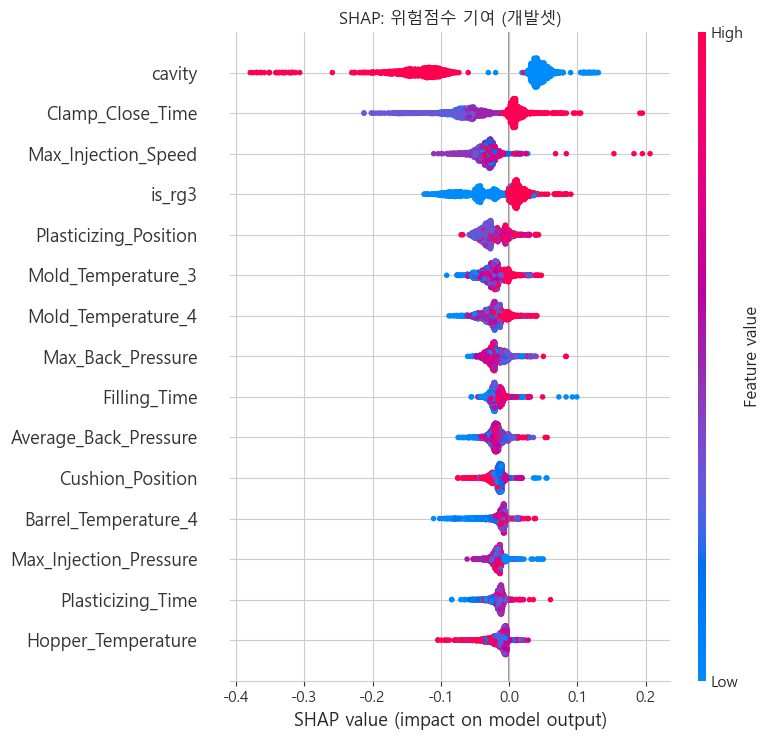

In [62]:
import shap

from src.experiments import shap_positive

sv1 = shap_positive(final, X_dev)
shap.summary_plot(sv1, X_dev, max_display=15, show=False)
plt.title("SHAP: 위험점수 기여 (개발셋)"); plt.tight_layout(); plt.show()

상위 변수: {'cavity': 0.0909, 'Clamp_Close_Time': 0.0442, 'Max_Injection_Speed': 0.0348, 'is_rg3': 0.0321, 'Plasticizing_Position': 0.0257, 'Mold_Temperature_3': 0.0238, 'Mold_Temperature_4': 0.0233, 'Max_Back_Pressure': 0.0206, 'Filling_Time': 0.0196, 'Average_Back_Pressure': 0.0193}


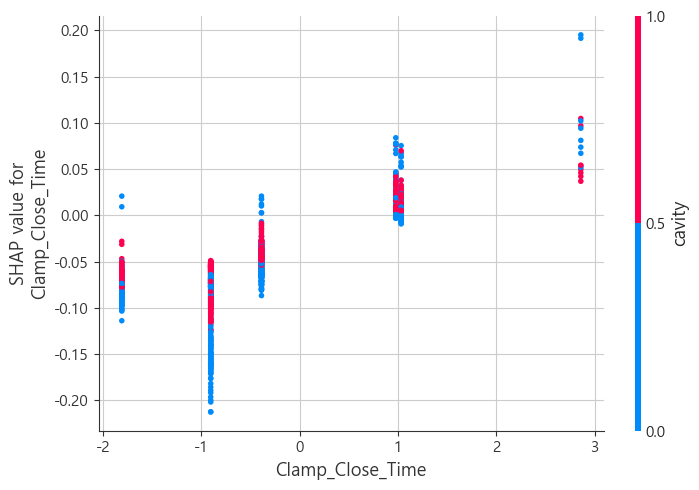

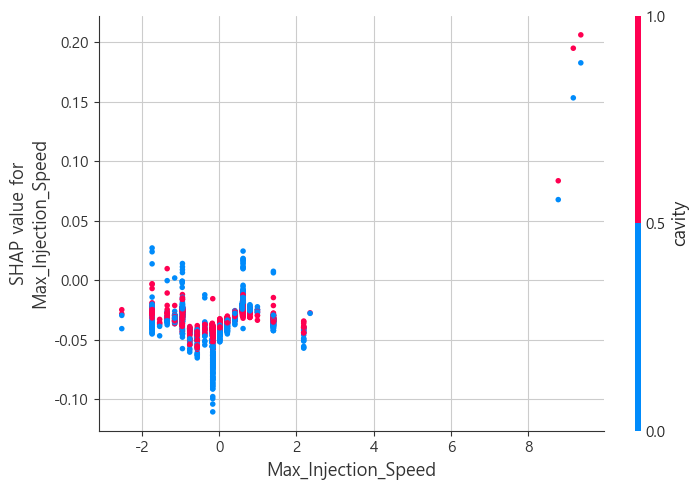

In [63]:
imp = pd.Series(np.abs(sv1).mean(0), index=X_dev.columns).sort_values(ascending=False)
TOP2 = [c for c in imp.index if c not in ("is_rg3", "cavity")][:2]
print("상위 변수:", imp.head(10).round(4).to_dict())
for c in TOP2:
    shap.dependence_plot(c, sv1, X_dev, interaction_index="auto", show=False)
    plt.tight_layout(); plt.show()

In [64]:
# 캐비티별·제품별 SHAP 순위 (cavity, is_rg3 제외)
print("■ 캐비티별"); display(ins.shap_rank_by_group(sv1, X_dev, dev["cavity"]))
print("■ 제품별");   display(ins.shap_rank_by_group(sv1, X_dev, dev["product"]))
stage_of = {v: s for s, vs in ins.STAGES.items() for v in vs}
st_imp = imp.drop(["is_rg3", "cavity"], errors="ignore").groupby(lambda v: stage_of.get(v, "기타")).sum().sort_values(ascending=False)
display(st_imp.round(4).rename("단계별 평균 |SHAP| 합").to_frame())
print("■ 제품별 기여 방향 (변수값과 SHAP 의 순위상관)")
display(ins.shap_direction(sv1, X_dev, dev["product"]).round(3))

■ 캐비티별


,0,1
0,"(Clamp_Close_Time, 0.0504)","(Clamp_Close_Time, 0.038)"
1,"(Max_Injection_Speed, 0.0366)","(Max_Injection_Speed, 0.033)"
2,"(Plasticizing_Position, 0.0304)","(Plasticizing_Position, 0.0209)"
3,"(Mold_Temperature_3, 0.0285)","(Mold_Temperature_3, 0.0191)"
4,"(Mold_Temperature_4, 0.0282)","(Filling_Time, 0.0187)"
5,"(Max_Back_Pressure, 0.0247)","(Mold_Temperature_4, 0.0183)"
6,"(Average_Back_Pressure, 0.0228)","(Max_Back_Pressure, 0.0165)"
7,"(Barrel_Temperature_4, 0.0215)","(Average_Back_Pressure, 0.0159)"


■ 제품별


,cn7,rg3
0,"(Clamp_Close_Time, 0.0519)","(Clamp_Close_Time, 0.0364)"
1,"(Max_Injection_Speed, 0.0351)","(Max_Injection_Speed, 0.0345)"
2,"(Plasticizing_Position, 0.0288)","(Mold_Temperature_4, 0.0252)"
3,"(Mold_Temperature_3, 0.0225)","(Mold_Temperature_3, 0.0251)"
4,"(Mold_Temperature_4, 0.0214)","(Plasticizing_Position, 0.0225)"
5,"(Filling_Time, 0.0213)","(Average_Back_Pressure, 0.0213)"
6,"(Max_Back_Pressure, 0.021)","(Max_Back_Pressure, 0.0202)"
7,"(Cushion_Position, 0.0183)","(Barrel_Temperature_4, 0.0202)"


,단계별 평균 |SHAP| 합
가소화(계량),0.211
충전(사출),0.0815
형개폐·사이클,0.0569
냉각(금형온도),0.0471
보압(V/P 전환),0.0305


■ 제품별 기여 방향 (변수값과 SHAP 의 순위상관)


,product,변수,평균 |SHAP|,값-기여 순위상관,방향
0,cn7,cavity,0.078,-0.866,값↑ → 점수↓
1,cn7,Clamp_Close_Time,0.052,0.869,값↑ → 점수↑
2,cn7,Max_Injection_Speed,0.035,0.555,값↑ → 점수↑
3,cn7,Plasticizing_Position,0.029,0.637,값↑ → 점수↑
4,cn7,Mold_Temperature_3,0.022,0.872,값↑ → 점수↑
5,cn7,Mold_Temperature_4,0.021,0.798,값↑ → 점수↑
6,rg3,cavity,0.105,-0.866,값↑ → 점수↓
7,rg3,Clamp_Close_Time,0.036,0.877,값↑ → 점수↑
8,rg3,Max_Injection_Speed,0.034,0.112,비단조/약함
9,rg3,Mold_Temperature_4,0.025,-0.004,비단조/약함


In [65]:
r0 = ins.shap_rank_by_group(sv1, X_dev, dev["cavity"])
top3v = ", ".join(imp.drop(['is_rg3', 'cavity'], errors='ignore').index[:3])
display(Markdown(f"""공정변수 중 기여가 큰 변수는 {top3v} 이고, 단계로 묶으면 {st_imp.index[0]}, {st_imp.index[1]} 순이다(단계 합계는 변수가 많은 단계가 유리하다). 추정 캐비티 0 과 1 의 상위 3개는 각각 {", ".join(v for v, _ in r0[0].head(3))} / {", ".join(v for v, _ in r0[1].head(3))} 이다.

SHAP 은 개발셋에서 계산한 모델 설명이며 인과 관계가 아니다. 현장 점검은 {top3v} 설정값부터 확인하도록 제안하고, 개별 제품에는 상위 3개를 예측 기여 변수(contrib_1~3)로 보여 준다(4-5). 변수를 바꿨을 때의 효과는 공정 실험으로 확인해야 한다."""))

공정변수 중 기여가 큰 변수는 Clamp_Close_Time, Max_Injection_Speed, Plasticizing_Position 이고, 단계로 묶으면 가소화(계량), 충전(사출) 순이다(단계 합계는 변수가 많은 단계가 유리하다). 추정 캐비티 0 과 1 의 상위 3개는 각각 Clamp_Close_Time, Max_Injection_Speed, Plasticizing_Position / Clamp_Close_Time, Max_Injection_Speed, Plasticizing_Position 이다.

SHAP 은 개발셋에서 계산한 모델 설명이며 인과 관계가 아니다. 현장 점검은 Clamp_Close_Time, Max_Injection_Speed, Plasticizing_Position 설정값부터 확인하도록 제안하고, 개별 제품에는 상위 3개를 예측 기여 변수(contrib_1~3)로 보여 준다(4-5). 변수를 바꿨을 때의 효과는 공정 실험으로 확인해야 한다.

### 3-2. 상위 2개 변수 구간별 불량률
각 칸에 불량률과 '불량 수/행 수'를 표시했다. 교차표일 뿐 상호작용을 통계적으로 검정한 것은 아니다.

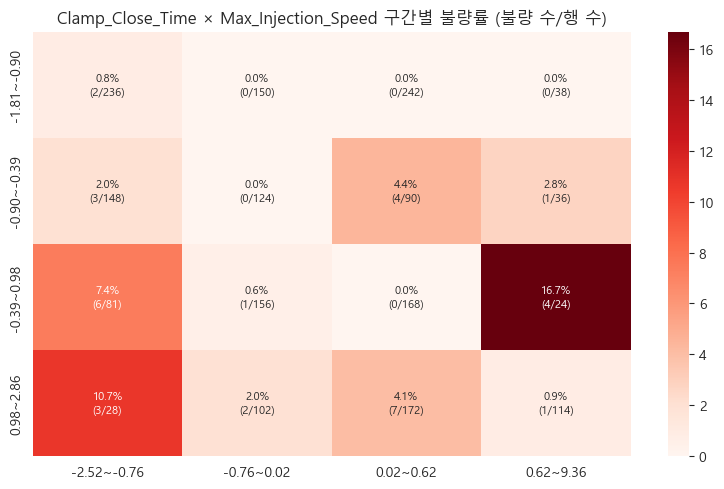

In [66]:
tmp = dev.copy()
for c in TOP2:
    tmp[c + "_bin"] = pd.qcut(tmp[c], 4, duplicates="drop")
grp = tmp.groupby([TOP2[0] + "_bin", TOP2[1] + "_bin"], observed=False)[TARGET]
rate = grp.mean().unstack() * 100
n, k = grp.size().unstack(), grp.sum().unstack()
lab = lambda idx: [f"{iv.left:.2f}~{iv.right:.2f}" for iv in idx]
for t in (rate, n, k):
    t.index, t.columns = lab(t.index), lab(t.columns)
annot = rate.round(1).astype(str) + "%\n(" + k.fillna(0).astype(int).astype(str) + "/" + n.fillna(0).astype(int).astype(str) + ")"
annot = annot.where(n > 0, "-")
plt.figure(figsize=(8, 5))
sns.heatmap(rate, annot=annot, fmt="", cmap="Reds", annot_kws={"fontsize": 8})
plt.title(f"{TOP2[0]} × {TOP2[1]} 구간별 불량률 (불량 수/행 수)"); plt.tight_layout(); plt.show()

In [67]:
cell = rate.stack().idxmax()
display(Markdown(f"""불량률이 가장 높은 칸은 {TOP2[0]} {cell[0]} × {TOP2[1]} {cell[1]} 로 {rate.stack().max():.1f}% ({int(k.loc[cell])}/{int(n.loc[cell])}) 이다. 칸마다 불량이 몇 건뿐이라 우연일 수 있으므로, 이 조합은 확인할 가설로 두고 같은 조건이 다시 나타날 때 표본 검사로 불량률을 추적한다."""))

불량률이 가장 높은 칸은 Clamp_Close_Time -0.39~0.98 × Max_Injection_Speed 0.62~9.36 로 16.7% (4/24) 이다. 칸마다 불량이 몇 건뿐이라 우연일 수 있으므로, 이 조합은 확인할 가설로 두고 같은 조건이 다시 나타날 때 표본 검사로 불량률을 추적한다.

### 3-3. FN(미탐지)과 FP(오경보): 제품별 상위 20% 검사 기준
운영 방식(2-1-1 의 C)대로 제품별 위험점수 상위 20% 를 검사한다고 보고 오류를 정의한다.
- TP: 검사 대상에 든 불량, FN: 검사 대상에서 빠진 불량(유출), FP: 검사했지만 양품, TN: 나머지
- 개발셋 OOF(5회 반복 평균 점수) 기준. 분모가 0 인 비율은 N/A 로 표시한다.

In [68]:
display(pd.crosstab([oof["product"], oof["cavity"]], oof["op_type"], margins=True))
OP = {p: ins.operating_metrics(d[TARGET], d["oof_prob"]) | {"Recall@20%": ((d.op_type == "TP").sum() / d[TARGET].sum())}
      for p, d in oof.groupby("product")}
display(pd.DataFrame(OP).round(3))

op_type         FN   FP    TN  TP   All
product cavity                         
cn7     0        0  124   349  10   483
        1        1   57   422   2   482
rg3     0       10  177   275  10   472
        1        1    2   469   0   472
All             12  360  1515  22  1909

,cn7,rg3
Precision@20%,0.062,0.053
F1@20%,0.117,0.095
Recall@20%,0.923,0.476


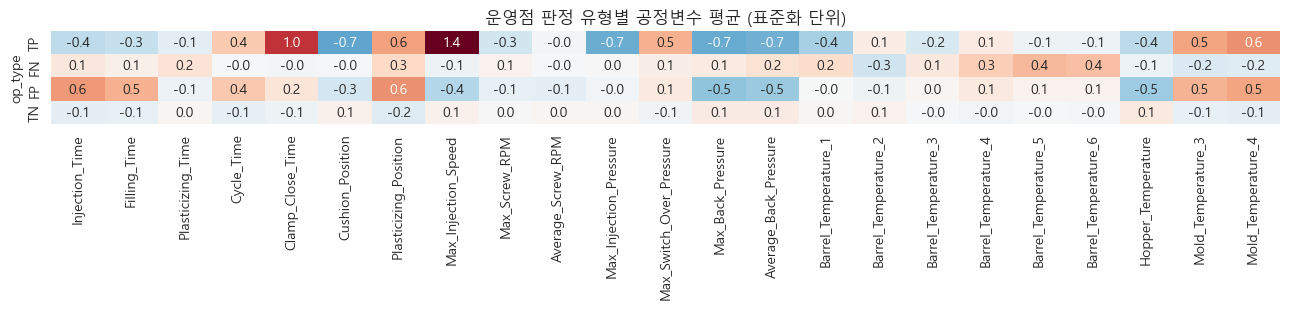

In [69]:
prof = oof.groupby("op_type")[use].mean().loc[["TP", "FN", "FP", "TN"]]
plt.figure(figsize=(13, 3.2))
sns.heatmap(prof, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar=False)
plt.title("운영점 판정 유형별 공정변수 평균 (표준화 단위)"); plt.tight_layout(); plt.show()

In [70]:
# 오류 집중 조건: 공정변수 구간, 생산순번 구간, 캐비티, 운전구간 군집
conc = pd.read_csv(OUT_DIR / "op_concentration.csv")
for axis_name in ["생산순번 구간", "캐비티", "운전구간 군집", "공정변수"]:
    print(f"■ {axis_name}")
    display(na(conc[conc["축"] == axis_name].drop(columns="축")))

■ 생산순번 구간


,항목,구간,n,불량,TP,FN,FP,FN 비율(불량 중),FP 비율(양품 중)
20,CN7,0~20% (순번 0~238),193,13,12,1,125,0.077,0.694
21,CN7,20~40% (순번 239~479),193,0,0,0,48,N/A,0.249
22,CN7,40~60% (순번 480~728),193,0,0,0,1,N/A,0.005
23,CN7,60~80% (순번 729~965),193,0,0,0,3,N/A,0.016
24,CN7,80~100% (순번 966~1210),193,0,0,0,4,N/A,0.021
25,RG3,0~20% (순번 1215~1449),189,4,1,3,39,0.75,0.211
26,RG3,20~40% (순번 1450~1680),189,8,4,4,46,0.5,0.254
27,RG3,40~60% (순번 1683~1910),188,3,2,1,35,0.333,0.189
28,RG3,60~80% (순번 1913~2153),189,3,2,1,41,0.333,0.22
29,RG3,80~100% (순번 2154~2392),189,3,1,2,18,0.667,0.097


■ 캐비티


,항목,구간,n,불량,TP,FN,FP,FN 비율(불량 중),FP 비율(양품 중)
30,제품·캐비티,CN7 캐비티0,483,10,10,0,124,0,0.262
31,제품·캐비티,CN7 캐비티1,482,3,2,1,57,0.333,0.119
32,제품·캐비티,RG3 캐비티0,472,20,10,10,177,0.5,0.392
33,제품·캐비티,RG3 캐비티1,472,1,0,1,2,1,0.004


■ 운전구간 군집


,항목,구간,n,불량,TP,FN,FP,FN 비율(불량 중),FP 비율(양품 중)
34,제품·군집,CN7 군집0,664,4,4,0,6,0,0.009
35,제품·군집,CN7 군집1,299,9,8,1,173,0.111,0.597
36,제품·군집,CN7 군집2,2,0,0,0,2,N/A,1
37,제품·군집,RG3 군집0,494,8,3,5,76,0.625,0.156
38,제품·군집,RG3 군집1,450,13,7,6,103,0.462,0.236


■ 공정변수


,항목,구간,n,불량,TP,FN,FP,FN 비율(불량 중),FP 비율(양품 중)
0,Clamp_Close_Time,-1.81 ~ -0.90,666,2,1,1,95,0.5,0.143
1,Clamp_Close_Time,-0.90 ~ -0.39,398,8,1,7,90,0.875,0.231
2,Clamp_Close_Time,-0.39 ~ 0.98,429,11,10,1,89,0.091,0.213
3,Clamp_Close_Time,0.98 ~ 2.86,416,13,10,3,86,0.231,0.213
4,Max_Injection_Speed,-2.52 ~ -0.76,493,14,9,5,193,0.357,0.403
5,Max_Injection_Speed,-0.76 ~ 0.02,532,3,2,1,60,0.333,0.113
6,Max_Injection_Speed,0.02 ~ 0.62,672,11,7,4,81,0.364,0.123
7,Max_Injection_Speed,0.62 ~ 9.36,212,6,4,2,26,0.333,0.126
8,Plasticizing_Position,-2.88 ~ -0.70,610,7,6,1,59,0.143,0.098
9,Plasticizing_Position,-0.70 ~ -0.52,352,0,0,0,2,N/A,0.006


In [71]:
# 깊이 3 의사결정나무로 뽑은 오류 규칙 (FN: 불량 중 놓친 것, FP: 양품 중 오경보)
for kind in ["FN", "FP"]:
    print(f"■ {kind} 규칙 (class 1 = {kind}, weights = [아님, {kind}] 건수)")
    print((OUT_DIR / f"op_rules_{kind}.txt").read_text(encoding="utf-8"))
    display(pd.read_csv(OUT_DIR / f"op_rules_{kind}_leaves.csv").head(4).round(3))

■ FN 규칙 (class 1 = FN, weights = [아님, FN] 건수)
|--- Clamp_Close_Time <= 0.30
|   |--- Barrel_Temperature_1 <= -0.02
|   |   |--- weights: [2.00, 1.00] class: 0
|   |--- Barrel_Temperature_1 >  -0.02
|   |   |--- weights: [0.00, 7.00] class: 1
|--- Clamp_Close_Time >  0.30
|   |--- Hopper_Temperature <= 0.51
|   |   |--- Injection_Time <= 1.48
|   |   |   |--- weights: [16.00, 0.00] class: 0
|   |   |--- Injection_Time >  1.48
|   |   |   |--- weights: [2.00, 1.00] class: 0
|   |--- Hopper_Temperature >  0.51
|   |   |--- weights: [2.00, 3.00] class: 1



,leaf,n,FN,FN 비율
0,3,7,7,1
1,8,5,3,0.6
2,2,3,1,0.333
3,7,3,1,0.333


■ FP 규칙 (class 1 = FP, weights = [아님, FP] 건수)
|--- Filling_Time <= 0.96
|   |--- cavity <= 0.50
|   |   |--- Plasticizing_Position <= -0.36
|   |   |   |--- weights: [417.00, 57.00] class: 0
|   |   |--- Plasticizing_Position >  -0.36
|   |   |   |--- weights: [196.00, 159.00] class: 0
|   |--- cavity >  0.50
|   |   |--- Plasticizing_Position <= 1.39
|   |   |   |--- weights: [787.00, 4.00] class: 0
|   |   |--- Plasticizing_Position >  1.39
|   |   |   |--- weights: [52.00, 7.00] class: 0
|--- Filling_Time >  0.96
|   |--- Clamp_Close_Time <= 0.04
|   |   |--- cavity <= 0.50
|   |   |   |--- weights: [11.00, 48.00] class: 1
|   |   |--- cavity >  0.50
|   |   |   |--- weights: [48.00, 11.00] class: 0
|   |--- Clamp_Close_Time >  0.04
|   |   |--- Barrel_Temperature_1 <= 0.17
|   |   |   |--- weights: [0.00, 45.00] class: 1
|   |   |--- Barrel_Temperature_1 >  0.17
|   |   |   |--- weights: [4.00, 29.00] class: 1



,leaf,n,FP,FP 비율
0,13,45,45,1
1,14,33,29,0.879
2,10,59,48,0.814
3,4,355,159,0.448


In [72]:
ot = oof.groupby("product")["op_type"].value_counts().unstack(fill_value=0)
seq = conc[conc["축"] == "생산순번 구간"]
cn7s = seq[seq["항목"] == "CN7"]
fp_top = cn7s.sort_values("FP", ascending=False).iloc[0]
cav = conc[conc["축"] == "캐비티"].set_index("구간")
fnl = pd.read_csv(OUT_DIR / "op_rules_FN_leaves.csv").iloc[0]
display(Markdown(f"""- CN7 은 불량 {ot.loc['cn7',['TP','FN']].sum()}건 중 {ot.loc['cn7','TP']}건을 잡고 {ot.loc['cn7','FN']}건을 놓쳤고, RG3 는 {ot.loc['rg3',['TP','FN']].sum()}건 중 {ot.loc['rg3','TP']}건을 잡았다. 놓친 불량은 대부분 RG3 다.
- CN7 오경보는 생산순번 {fp_top['구간']} 에 {int(fp_top.FP)}건이 몰려 있다. 불량 다발 시기의 양품도 공정값이 비슷해 함께 검사 대상에 오른 것으로, 이 시기에는 강화검사로 보는 편이 맞다.
- 추정 캐비티별 FN 비율: {", ".join(f"{i} {r['FN 비율(불량 중)']:.2f}" for i, r in cav.iterrows() if r['불량'] > 0)}
- FN 규칙나무에서 가장 순수한 잎은 {int(fnl.n)}건 중 {int(fnl.FN)}건이 FN 이다.

규칙나무는 불량 34건으로 만든 요약이라 새 데이터에서 그대로 성립한다고 볼 수 없다. RG3 의 FN 은 충돌 패턴 때문이라 모델 조정으로 줄이기 어려워 추정 캐비티0 샘플 검사로 보완하고, CN7 가동 초기 오경보는 강화검사 비용으로 본다."""))

- CN7 은 불량 13건 중 12건을 잡고 1건을 놓쳤고, RG3 는 21건 중 10건을 잡았다. 놓친 불량은 대부분 RG3 다.
- CN7 오경보는 생산순번 0~20% (순번 0~238) 에 125건이 몰려 있다. 불량 다발 시기의 양품도 공정값이 비슷해 함께 검사 대상에 오른 것으로, 이 시기에는 강화검사로 보는 편이 맞다.
- 추정 캐비티별 FN 비율: CN7 캐비티0 0.00, CN7 캐비티1 0.33, RG3 캐비티0 0.50, RG3 캐비티1 1.00
- FN 규칙나무에서 가장 순수한 잎은 7건 중 7건이 FN 이다.

규칙나무는 불량 34건으로 만든 요약이라 새 데이터에서 그대로 성립한다고 볼 수 없다. RG3 의 FN 은 충돌 패턴 때문이라 모델 조정으로 줄이기 어려워 추정 캐비티0 샘플 검사로 보완하고, CN7 가동 초기 오경보는 강화검사 비용으로 본다.

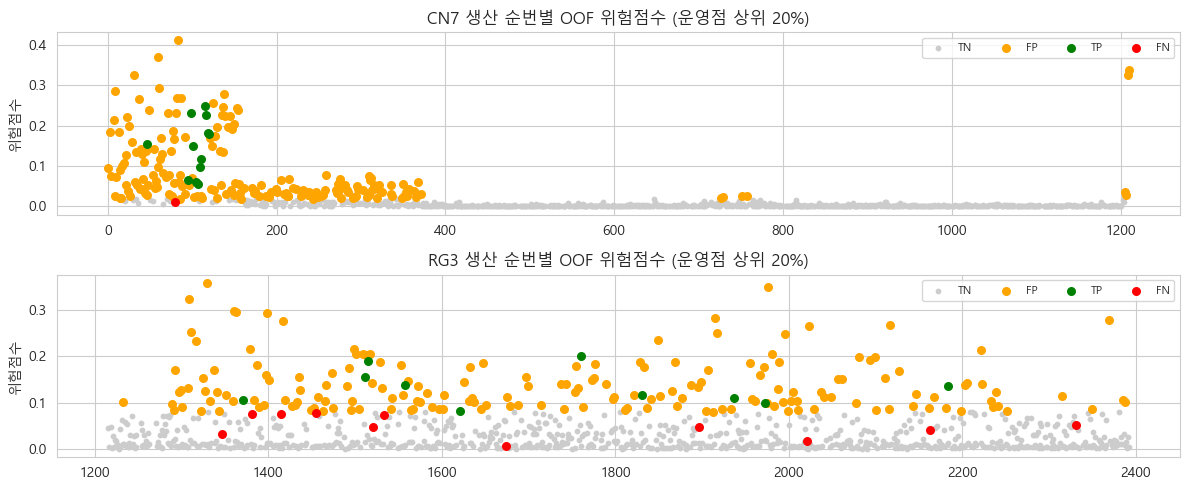

In [73]:
# 생산 순번별 위험점수와 판정 유형
fig, axes = plt.subplots(2, 1, figsize=(12, 5))
for ax, (p, d) in zip(axes, oof.groupby("product")):
    for t, col in [("TN", "#cccccc"), ("FP", "orange"), ("TP", "green"), ("FN", "red")]:
        s = d[d.op_type == t]
        ax.scatter(s[INDEX_COL], s["oof_prob"], s=10 if t == "TN" else 30, c=col, label=t)
    ax.set_title(f"{p.upper()} 생산 순번별 OOF 위험점수 (운영점 상위 20%)"); ax.legend(ncol=4, fontsize=8, loc="upper right"); ax.set_ylabel("위험점수")
plt.tight_layout(); plt.show()

### 3-4. 운전구간 군집
공정값만으로 K-평균 군집(실루엣 점수로 k 선택)을 만들고 군집별 불량률을 비교한다.
라벨 없이 만든 군집이 불량 다발 구간과 겹치면 가동 초기 강화검사 같은 운영 규칙의 근거가 된다.

,product,cluster,rows,fails,fail_rate(%),idx_start,idx_end,k,silhouette
0,cn7,0,838,6,0.72,115,1206,3,0.317
1,cn7,1,369,11,2.98,0,374,3,0.317
2,cn7,2,4,0,0,1207,1210,3,0.317
3,rg3,0,636,11,1.73,1303,2392,2,0.2
4,rg3,1,546,14,2.56,1211,2284,2,0.2


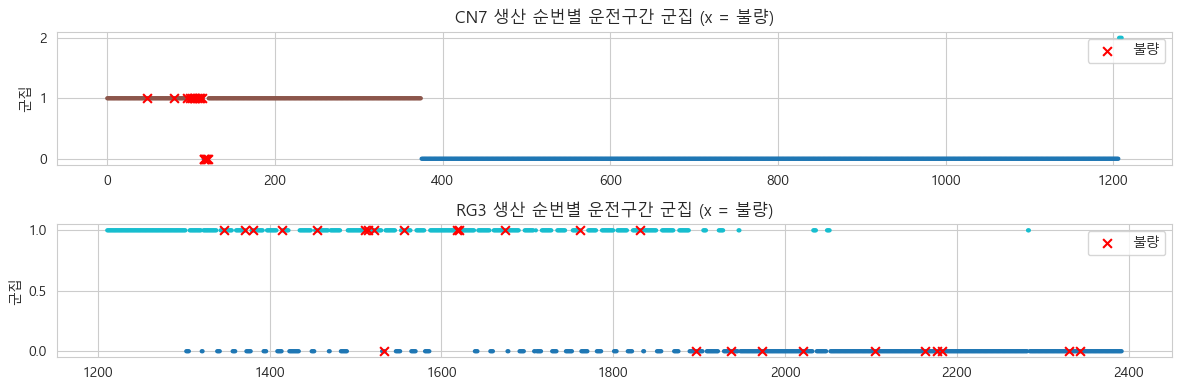

In [74]:
rc = pd.read_csv(OUT_DIR / "regime_clusters.csv")
rc["fail_rate(%)"] = (rc["fail_rate"] * 100).round(2)
display(rc[["product", "cluster", "rows", "fails", "fail_rate(%)", "idx_start", "idx_end", "k", "silhouette"]].round(3))

asg = pd.read_csv(OUT_DIR / "regime_cluster_assign.csv")
fig, axes = plt.subplots(2, 1, figsize=(12, 4))
for ax, (p, d) in zip(axes, asg.groupby("product")):
    ax.scatter(d[INDEX_COL], d["cluster"], c=d["cluster"], cmap="tab10", s=4)
    f = d[d[TARGET] == 1]
    ax.scatter(f[INDEX_COL], f["cluster"], marker="x", c="red", s=40, label="불량")
    ax.set_title(f"{p.upper()} 생산 순번별 운전구간 군집 (x = 불량)"); ax.set_ylabel("군집"); ax.legend()
plt.tight_layout(); plt.show()

In [75]:
best_c = rc.sort_values("fail_rate", ascending=False).iloc[0]
display(Markdown(f"""라벨 없이 만든 군집 중 {best_c['product'].upper()} 군집{int(best_c.cluster)}(순번 {int(best_c.idx_start)}~{int(best_c.idx_end)})의 불량률이 {best_c.fail_rate*100:.1f}% 로 가장 높다. CN7 은 가동 초기 구간이 별도 군집으로 나뉘고, RG3 는 군집 간 차이가 작다.
공정값만으로도 불안정 구간을 어느 정도 구분할 수 있어, 라벨 없이 작동하는 공정 흔들림 경보(4-3)를 검토했다."""))

라벨 없이 만든 군집 중 CN7 군집1(순번 0~374)의 불량률이 3.0% 로 가장 높다. CN7 은 가동 초기 구간이 별도 군집으로 나뉘고, RG3 는 군집 간 차이가 작다.
공정값만으로도 불안정 구간을 어느 정도 구분할 수 있어, 라벨 없이 작동하는 공정 흔들림 경보(4-3)를 검토했다.

## 4. 현장 활용방안: 검사 우선순위
모델은 기존 품질검사를 대체하지 않는다. 같은 검사 용량에서 불량을 더 많이 잡도록 검사 순서를 정하는 데 쓴다.

| 범위 | 검증 결과 | 적용 수준 |
|---|---|---|
| CN7 | 같은 기간 CV 에서 상위 20% 검사로 대부분 포착. 불량이 가동 초기 한 구간뿐이라 과거→미래 검증은 불가 | 가동 초기 강화검사 규칙과 모델 순위를 함께 쓰고, 시범 적용으로 추가 검증 |
| RG3 | 불량 전부가 라벨 충돌, 테스트 성능은 무작위 수준 | 모델 단독 사용 불가. 추정 캐비티0 샘플 검사와 기존 검사 유지, 추가 센서 데이터 필요 |

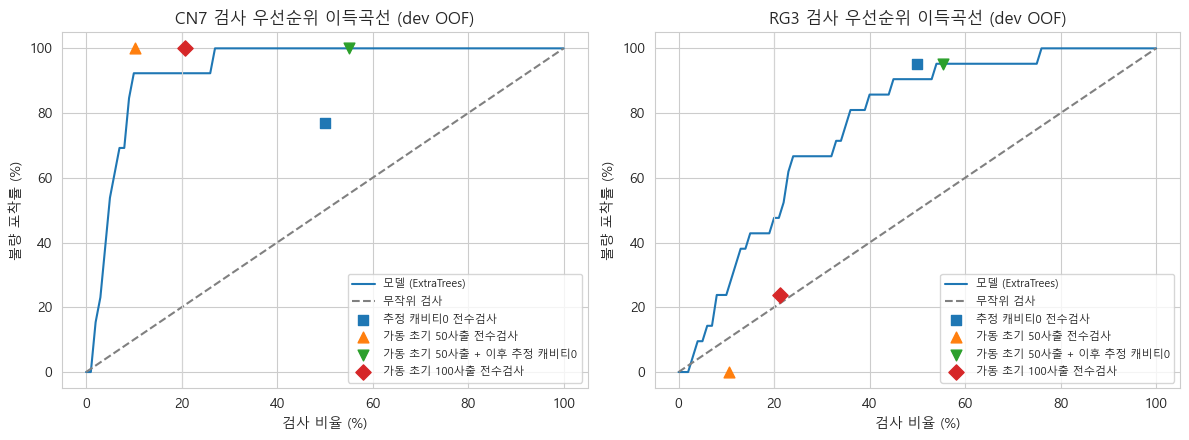

In [76]:
rb = pd.read_csv(OUT_DIR / "rule_baselines.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (p, d) in zip(axes, oof.groupby("product")):
    x, r = ins.gain_curve(d[TARGET].to_numpy(), d["oof_prob"].to_numpy())
    ax.plot(x * 100, r * 100, label=f"모델 ({BEST_MODEL})")
    ax.plot([0, 100], [0, 100], "--", c="gray", label="무작위 검사")
    for (_, row), mk in zip(rb[(rb.scope == p) & rb.rule.str.contains("캐비티0 전수|초기 50사출|초기 100사출 전수")].iterrows(), "s^vD"):
        ax.scatter(row["검사 비율"] * 100, row["규칙 포착률"] * 100, marker=mk, s=60, zorder=3, label=row.rule)
    ax.axvline(20, c="lightgray", lw=.8)
    ax.set_title(f"{p.upper()} 검사 우선순위 이득곡선 (dev OOF)"); ax.set_xlabel("검사 비율 (%)"); ax.set_ylabel("불량 포착률 (%)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [77]:
cap = pd.read_csv(OUT_DIR / "capacity_table.csv")
print("■ 검사 용량별 포착·미탐지 (개발셋 OOF, 동점은 생산 순번 우선)")
for pol in ["제품별 할당", "통합 순위"]:
    print(f"  [{pol}]")
    display(na(cap[cap["정책"] == pol].drop(columns="정책").set_index(["검사 용량", "scope"])))
print("■ 규칙 베이스라인 vs 같은 검사량의 모델")
display(na(rb))

■ 검사 용량별 포착·미탐지 (개발셋 OOF, 동점은 생산 순번 우선)
  [제품별 할당]


대상 수 검사 수 실제 검사 비율 불량 수 포착 불량 미탐지 불량   포착률 검사 중 불량 비율
검사 용량 scope                                                       
0.05  all    1909   97    0.051   34     9     25 0.265      0.093
      cn7     965   49    0.051   13     7      6 0.538      0.143
      rg3     944   48    0.051   21     2     19 0.095      0.042
0.1   all    1909  192    0.101   34    17     17   0.5      0.089
      cn7     965   97    0.101   13    12      1 0.923      0.124
      rg3     944   95    0.101   21     5     16 0.238      0.053
0.2   all    1909  382      0.2   34    22     12 0.647      0.058
      cn7     965  193      0.2   13    12      1 0.923      0.062
      rg3     944  189      0.2   21    10     11 0.476      0.053
0.3   all    1909  574    0.301   34    27      7 0.794      0.047
      cn7     965  290    0.301   13    13      0     1      0.045
      rg3     944  284    0.301   21    14      7 0.667      0.049

  [통합 순위]


대상 수 검사 수 실제 검사 비율 불량 수 포착 불량 미탐지 불량   포착률 검사 중 불량 비율
검사 용량 scope                                                       
0.05  all    1909   96     0.05   34     9     25 0.265      0.094
      cn7     965   43    0.045   13     6      7 0.462       0.14
      rg3     944   53    0.056   21     3     18 0.143      0.057
0.1   all    1909  191      0.1   34    16     18 0.471      0.084
      cn7     965   59    0.061   13     8      5 0.615      0.136
      rg3     944  132     0.14   21     8     13 0.381      0.061
0.2   all    1909  382      0.2   34    26      8 0.765      0.068
      cn7     965   91    0.094   13    12      1 0.923      0.132
      rg3     944  291    0.308   21    14      7 0.667      0.048
0.3   all    1909  573      0.3   34    31      3 0.912      0.054
      cn7     965  148    0.153   13    12      1 0.923      0.081
      rg3     944  425     0.45   21    19      2 0.905      0.045

■ 규칙 베이스라인 vs 같은 검사량의 모델


,scope,rule,검사 비율,규칙 포착률,모델 포착률(같은 검사량),모델 추가 포착(건),불량 수
0,all,추정 캐비티0 전수검사,0.5,0.882,0.941,2,34
1,all,가동 초기 50사출 전수검사,0.104,0.382,0.529,5,34
2,all,가동 초기 50사출 + 이후 추정 캐비티0,0.552,0.971,0.971,0,34
3,all,가동 초기 100사출 전수검사,0.209,0.529,0.647,4,34
4,all,가동 초기 100사출 + 이후 추정 캐비티0,0.605,0.971,0.971,0,34
5,all,가동 초기 150사출 전수검사,0.314,0.676,0.794,4,34
6,all,가동 초기 150사출 + 이후 추정 캐비티0,0.657,0.971,0.971,0,34
7,cn7,추정 캐비티0 전수검사,0.501,0.769,1,3,13
8,cn7,가동 초기 50사출 전수검사,0.103,1,0.923,-1,13
9,cn7,가동 초기 50사출 + 이후 추정 캐비티0,0.551,1,1,0,13


In [78]:
cp = cap.set_index(["정책", "검사 용량", "scope"])
a20, i20 = cp.loc[("제품별 할당", 0.2, "all")], cp.loc[("통합 순위", 0.2, "all")]
r3 = cp.loc[("통합 순위", 0.2, "rg3")]
display(Markdown(f"""검사 용량 20% 에서 제품별 할당은 {int(a20['검사 수'])}개를 검사해 불량 {int(a20['불량 수'])}건 중 {int(a20['포착 불량'])}건을 잡고 {int(a20['미탐지 불량'])}건을 놓친다. 통합 순위는 {int(i20['포착 불량'])}건을 잡지만 RG3 검사 비율이 {r3['실제 검사 비율']*100:.0f}% 로 바뀐다.
통합 순위는 점수가 높게 나오는 제품에 검사가 몰리고 두 제품의 점수 척도가 같다는 보장이 없어, 제품별 할당을 기본으로 한다. 개발셋 OOF 합산 기준이라 2장의 Recall@20%(fold 평균)와 값이 조금 다르다."""))

검사 용량 20% 에서 제품별 할당은 382개를 검사해 불량 34건 중 22건을 잡고 12건을 놓친다. 통합 순위는 26건을 잡지만 RG3 검사 비율이 31% 로 바뀐다.
통합 순위는 점수가 높게 나오는 제품에 검사가 몰리고 두 제품의 점수 척도가 같다는 보장이 없어, 제품별 할당을 기본으로 한다. 개발셋 OOF 합산 기준이라 2장의 Recall@20%(fold 평균)와 값이 조금 다르다.

In [79]:
r = rb.set_index(["scope", "rule"])
c0 = r.loc[("all", "추정 캐비티0 전수검사")]
e50 = r.loc[("cn7", "가동 초기 50사출 전수검사")]
r3 = r.loc[("rg3", "추정 캐비티0 전수검사")]
win = rb[rb["모델 추가 포착(건)"] < 0]
display(Markdown(f"""- 추정 캐비티0 전수검사(검사 {c0['검사 비율']*100:.0f}%)는 불량의 {c0['규칙 포착률']*100:.0f}% 를 잡고, 같은 검사량에서 모델은 {c0['모델 포착률(같은 검사량)']*100:.0f}% ({int(c0['모델 추가 포착(건)']):+d}건)다. RG3 만 보면 규칙 {r3['규칙 포착률']*100:.0f}%, 모델 {r3['모델 포착률(같은 검사량)']*100:.0f}% 다.
- CN7 가동 초기 50사출 전수검사(검사 {e50['검사 비율']*100:.1f}%)는 불량의 {e50['규칙 포착률']*100:.0f}% 를 잡아 같은 검사량의 모델({e50['모델 포착률(같은 검사량)']*100:.0f}%)보다 {'높다' if e50['규칙 포착률'] > e50['모델 포착률(같은 검사량)'] else '낮다'}.
- 규칙이 모델보다 나은 경우: {", ".join(f"{a.scope}/{a.rule}" for a in win.itertuples()) or "없음"}

다만 '초기 50사출'은 불량이 초기에 몰린 것을 보고 정한 규칙이라 새 가동에서도 같은 효과가 난다는 보장이 없다. 그래서 가동 초기·금형 교체 직후에는 규칙으로 강화검사하고, 안정 구간에는 모델 상위 k% 를 검사하며, RG3 는 추정 캐비티0 샘플 검사를 병행하는 방식을 제안한다."""))

- 추정 캐비티0 전수검사(검사 50%)는 불량의 88% 를 잡고, 같은 검사량에서 모델은 94% (+2건)다. RG3 만 보면 규칙 95%, 모델 90% 다.
- CN7 가동 초기 50사출 전수검사(검사 10.3%)는 불량의 100% 를 잡아 같은 검사량의 모델(92%)보다 높다.
- 규칙이 모델보다 나은 경우: cn7/가동 초기 50사출 전수검사, cn7/가동 초기 100사출 전수검사, rg3/추정 캐비티0 전수검사

다만 '초기 50사출'은 불량이 초기에 몰린 것을 보고 정한 규칙이라 새 가동에서도 같은 효과가 난다는 보장이 없다. 그래서 가동 초기·금형 교체 직후에는 규칙으로 강화검사하고, 안정 구간에는 모델 상위 k% 를 검사하며, RG3 는 추정 캐비티0 샘플 검사를 병행하는 방식을 제안한다.

In [80]:
# 위험등급: 보정 확률의 개발셋 분위로 3단계
tm = json.loads((OUT_DIR / "test_metrics.json").read_text(encoding="utf-8"))
cut = tm["grade_cut"]
assert (cal_oof[INDEX_COL].to_numpy() == oof[INDEX_COL].to_numpy()).all()   # 같은 dev 행 순서
oof["prob_cal"] = cal_oof[f"prob_{CAL_METHOD}"].to_numpy()
oof["risk"] = pd.cut(oof["prob_cal"], [-np.inf, cut["주의"], cut["위험"], np.inf], labels=["정상", "주의", "위험"], right=False)
grade = oof.groupby("risk", observed=True).agg(n=(TARGET, "size"), 불량=(TARGET, "sum"), 불량률=(TARGET, "mean"),
                                             평균_보정확률=("prob_cal", "mean"))
grade["불량 중 비중"] = grade["불량"] / grade["불량"].sum()
display(grade.round(3))
print(f"경계값 ({CAL_METHOD} 보정 확률): 주의 ≥ {cut['주의']:.4f}, 위험 ≥ {cut['위험']:.4f}")

,n,불량,불량률,평균_보정확률,불량 중 비중
risk,,,,,
정상,1336,4,0.003,0.011,0.118
주의,382,16,0.042,0.019,0.471
위험,191,14,0.073,0.06,0.412


경계값 (sigmoid 보정 확률): 주의 ≥ 0.0146, 위험 ≥ 0.0272


In [81]:
display(Markdown(f"""위험 등급(상위 10%)의 실제 불량률은 {grade.loc['위험','불량률']*100:.1f}% 로 정상 등급({grade.loc['정상','불량률']*100:.2f}%)의 약 {grade.loc['위험','불량률']/max(grade.loc['정상','불량률'],1e-9):.0f}배이고, 불량의 {grade.loc['위험','불량 중 비중']*100:.0f}% 가 위험 등급에 있다. 위험 등급의 평균 보정 확률은 {grade.loc['위험','평균_보정확률']*100:.1f}% 로, 실제 불량률과의 차이는 운영 중에 확인해야 한다."""))

위험 등급(상위 10%)의 실제 불량률은 7.3% 로 정상 등급(0.30%)의 약 24배이고, 불량의 41% 가 위험 등급에 있다. 위험 등급의 평균 보정 확률은 6.0% 로, 실제 불량률과의 차이는 운영 중에 확인해야 한다.

### 4-1-1. 위험등급별 조치
| 등급 (보정 확률 기준) | 검사 | 재검사·공정 조치 | 예측 기여 변수 활용 |
|---|---|---|---|
| 정상 (개발셋 하위 70%) | 기존 정기 샘플링 + 무작위 표본 검사(4-4) | 없음 | 표시 안 함 |
| 주의 (70~90%) | 같은 추정 사출 그룹 중 1개 샘플 검사 | 연속 3사출 이상 주의면 설비 담당 확인 | 상위 변수의 설정값 이탈 여부 확인 |
| 위험 (상위 10%) | 같은 추정 사출 그룹 2개 모두 검사 | 불량이면 재검사 기준 강화, 해당 공정 단계(1-4-1) 설정값 점검 | 기여 변수가 같은 단계면 그 단계부터 확인 |
| 경보 구간 (4-3) | 경보 해제까지 강화 검사 | 가동 초기·금형 교체 직후처럼 안정화 확인 | - |

CN7 은 가동 초기(첫 50사출) 강화검사를 병행하고, RG3 는 등급과 별도로 추정 캐비티0 샘플 검사를 병행한다.
등급 경계는 개발셋 분위로 고정하고 재학습할 때만 바꾼다.

### 4-2. 비용 시나리오와 손익분기
검사 비용과 유출 비용 자료가 없어, 검사 1건 비용을 1, 불량 1건 유출 비용을 r 로 가정한 시나리오만 제시한다.
- 총비용 = 검사 수 × 1 + 놓친 불량 수 × r (제품별 상위 k% 검사)
- 손익분기: 보정 확률 p 인 제품은 p × r ≥ 1, 즉 p ≥ 1/r 이면 검사하는 편이 기대비용상 낫다. 보정 확률이 실제 빈도와 맞는다는 가정이 필요하다.

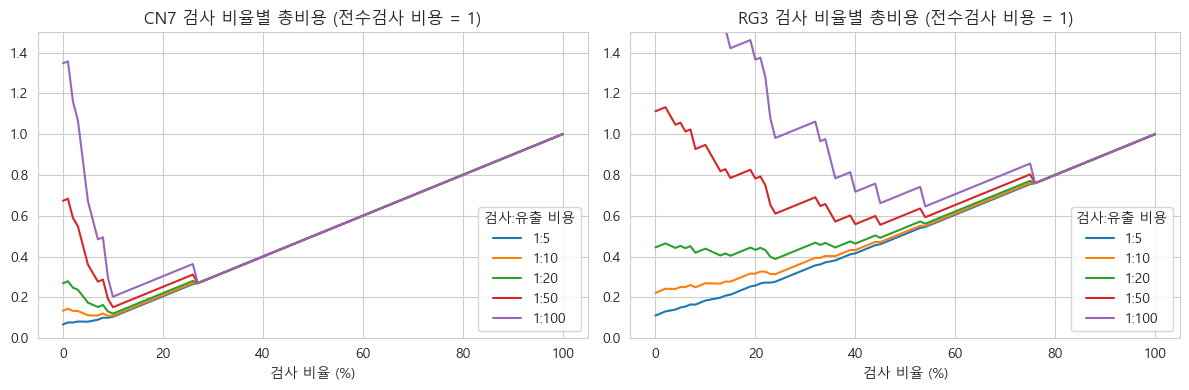

,product,ratio,검사 비율,총비용,전수검사 비용,무검사 비용,단순 대안 대비 절감
0,cn7,5,0,65,965,65,0
1,cn7,10,0.1,106.5,965,130,0.181
2,cn7,20,0.1,116.5,965,260,0.552
3,cn7,50,0.1,146.5,965,650,0.775
4,cn7,100,0.1,196.5,965,1300,0.796
5,rg3,5,0,105,944,105,0
6,rg3,10,0,210,944,210,0
7,rg3,20,0.24,366.6,944,420,0.127
8,rg3,50,0.45,524.8,944,1050,0.444
9,rg3,100,0.54,609.8,944,2100,0.354


In [82]:
cc = pd.read_csv(OUT_DIR / "cost_curves.csv")
cb = pd.read_csv(OUT_DIR / "cost_best.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (p, d) in zip(axes, cc.groupby("product")):
    for r, g in d.groupby("ratio"):
        ax.plot(g["검사 비율"] * 100, g["총비용"] / g["전수검사 비용"], label=f"1:{r}")
    ax.set_title(f"{p.upper()} 검사 비율별 총비용 (전수검사 비용 = 1)"); ax.set_xlabel("검사 비율 (%)"); ax.set_ylim(0, 1.5)
    ax.legend(title="검사:유출 비용")
plt.tight_layout(); plt.show()
display(cb[["product", "ratio", "검사 비율", "총비용", "전수검사 비용", "무검사 비용", "단순 대안 대비 절감"]].round(3))

In [83]:
be = pd.read_csv(OUT_DIR / "cost_breakeven.csv")
print("■ 손익분기 확률 이상인 제품만 검사할 때 (개발셋 OOF 보정 확률)")
display(na(be.pivot_table(index=["유출:검사 비용비", "손익분기 확률(1/r)"], columns="scope", values=["검사 비율", "포착률"], sort=False)))

■ 손익분기 확률 이상인 제품만 검사할 때 (개발셋 OOF 보정 확률)


검사 비율               포착률            
scope                    all   cn7   rg3   all   cn7   rg3
유출:검사 비용비 손익분기 확률(1/r)                                    
5:1       0.2          0.003 0.005     0     0     0     0
10:1      0.1          0.014 0.019  0.01 0.118 0.308     0
20:1      0.05         0.042 0.039 0.046 0.176 0.385 0.048
50:1      0.02         0.178 0.082 0.276 0.706 0.769 0.667
100:1     0.01         0.926  0.87 0.982     1     1     1

In [84]:
b = cb.set_index(["product", "ratio"])
display(Markdown(f"""가정한 비용비별 총비용 최소 검사 비율은 CN7 {", ".join(f"1:{r} {b.loc[('cn7',r),'검사 비율']*100:.0f}%" for r in (10, 20, 50, 100))} 이고, 1:50 에서는 전수검사·무검사 중 싼 쪽보다 비용이 {b.loc[('cn7',50),'단순 대안 대비 절감']*100:.0f}% 낮다. RG3 는 {', '.join(f"1:{r} {b.loc[('rg3',r),'검사 비율']*100:.0f}%" for r in (10, 20, 50, 100))} 로 가정에 따라 크게 달라진다.
r 은 실측값이 아니므로 기본 운영점은 상위 20% 로 두고, 현장 비용비가 정해지면 이 표로 제품별 검사 비율을 다시 정한다. RG3 는 유출 비용이 크면 검사 비율을 크게 올려야 해 모델의 비용 절감 효과가 작다."""))

가정한 비용비별 총비용 최소 검사 비율은 CN7 1:10 10%, 1:20 10%, 1:50 10%, 1:100 10% 이고, 1:50 에서는 전수검사·무검사 중 싼 쪽보다 비용이 77% 낮다. RG3 는 1:10 0%, 1:20 24%, 1:50 45%, 1:100 54% 로 가정에 따라 크게 달라진다.
r 은 실측값이 아니므로 기본 운영점은 상위 20% 로 두고, 현장 비용비가 정해지면 이 표로 제품별 검사 비율을 다시 정한다. RG3 는 유출 비용이 크면 검사 비율을 크게 올려야 해 모델의 비용 절감 효과가 작다.

### 4-3. 사전경보
제품별 생산 순서에 따라 두 신호에 이동평균(직전 10사출)과 CUSUM 알람을 건다. 알람 기준은 신호의 상위 10% 분위로 정했다.
- 공정 흔들림: 각 사출의 공정값이 직전 10사출 평균에서 벗어난 정도. 라벨 없이 과거 값만 쓴다.
- 모델 점수: 생산순번 블록 CV 의 위험점수 (같은 시기 사출을 학습에서 뺀 조건)
- 사전 감지 비율: 불량 사출 직전 10사출 안에 알람이 있었던 비율. 알람 후 window 내 불량 비율: 알람의 정밀도

,signal,product,rule,사출 수,알람 사출 비율,첫 알람 순번,첫 불량 순번,불량 사출 중 사전 감지 비율,알람 후 window 내 불량 비율
0,공정 흔들림,cn7,이동평균,483,0.099,31,47,1,0.312
1,공정 흔들림,cn7,CUSUM,483,0.101,71,47,0.455,0.082
2,공정 흔들림,rg3,이동평균,472,0.1,1291,1347,0.143,0.298
3,공정 흔들림,rg3,CUSUM,472,0.102,1285,1347,0.095,0.271
4,모델 점수,cn7,이동평균,483,0.099,153,47,0,0
5,모델 점수,cn7,CUSUM,483,0.101,313,47,0,0
6,모델 점수,rg3,이동평균,472,0.1,1221,1347,0.048,0.191
7,모델 점수,rg3,CUSUM,472,0.102,1253,1347,0.143,0.396


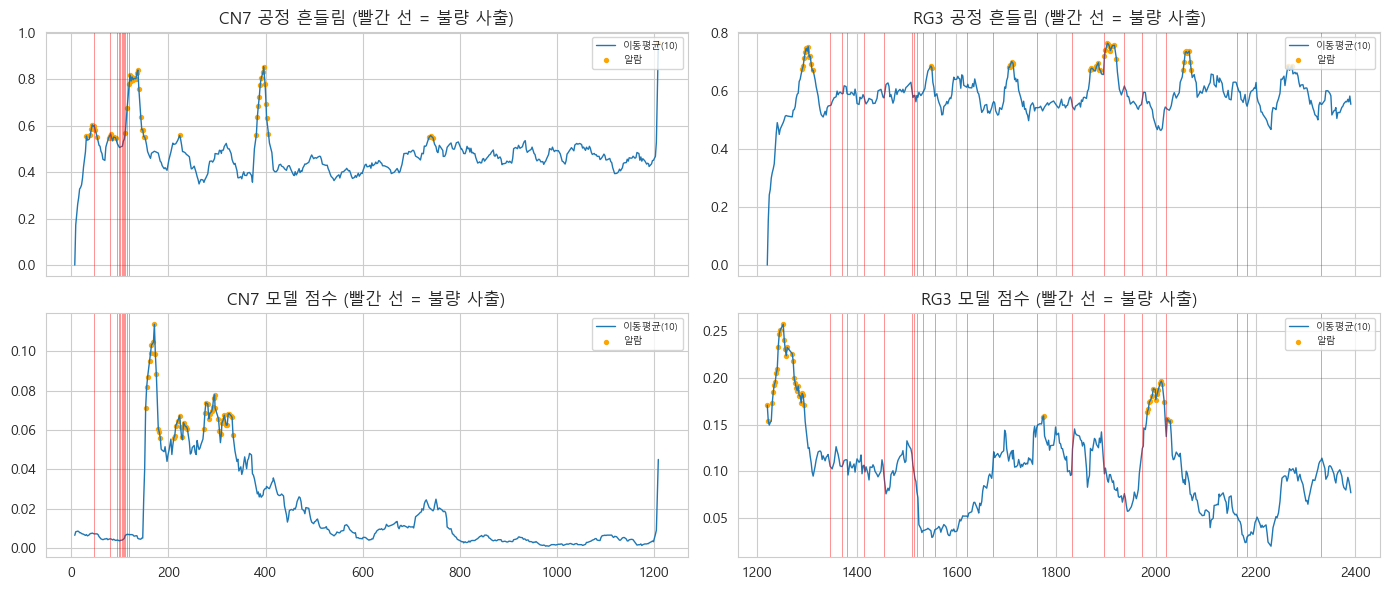

In [85]:
ews = pd.read_csv(OUT_DIR / "early_warning_series.csv")
ewm = pd.read_csv(OUT_DIR / "early_warning_summary.csv")
display(ewm.round(3))
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex="col")
for j, p in enumerate(["cn7", "rg3"]):
    for i, sig_name in enumerate(["공정 흔들림", "모델 점수"]):
        ax = axes[i, j]
        s = ews[(ews["product"] == p) & (ews["signal"] == sig_name)]
        ax.plot(s["idx"], s["ma"], lw=1, label="이동평균(10)")
        a = s[s["alarm_ma"]]
        ax.scatter(a["idx"], a["ma"], s=8, c="orange", label="알람")
        for x in s.loc[s.fails > 0, "idx"]:
            ax.axvline(x, c="red", lw=.6, alpha=.5)
        ax.set_title(f"{p.upper()} {sig_name} (빨간 선 = 불량 사출)"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

In [86]:
e = ewm.set_index(["signal", "product", "rule"])
pc = e.loc[("공정 흔들림", "cn7", "이동평균")]; mc = e.loc[("모델 점수", "cn7", "이동평균")]; pr = e.loc[("공정 흔들림", "rg3", "이동평균")]
display(Markdown(f"""CN7 의 공정 흔들림 경보는 첫 알람이 순번 {pc['첫 알람 순번']:.0f} 로 첫 불량({pc['첫 불량 순번']:.0f})보다 {'먼저' if pc['첫 알람 순번'] < pc['첫 불량 순번'] else '늦게'} 울렸고, 불량 사출의 {pc['불량 사출 중 사전 감지 비율']*100:.0f}% 를 직전 10사출 안에 감지했다(알람 비율 {pc['알람 사출 비율']*100:.0f}%, 알람 후 불량 비율 {pc['알람 후 window 내 불량 비율']*100:.0f}%).
모델 점수 경보는 첫 알람이 {mc['첫 알람 순번']:.0f} 로 {'첫 불량보다 늦고' if mc['첫 알람 순번'] > mc['첫 불량 순번'] else '첫 불량보다 앞서고'} 사전 감지 비율이 {mc['불량 사출 중 사전 감지 비율']*100:.0f}% 다. 처음 보는 불안정 구간은 모델이 학습한 적이 없기 때문이다(2-8 과 같은 결과). RG3 공정 흔들림 경보의 사전 감지는 {pr['불량 사출 중 사전 감지 비율']*100:.0f}% 로 약하다.

알람 기준을 같은 개발셋에서 정했고 CN7 불안정 구간이 한 번뿐이라 낙관적인 결과다. 사전경보는 공정 흔들림 신호로 운영하고, 경보 기간의 검사 결과를 라벨로 쌓아 재학습에 쓴다."""))

CN7 의 공정 흔들림 경보는 첫 알람이 순번 31 로 첫 불량(47)보다 먼저 울렸고, 불량 사출의 100% 를 직전 10사출 안에 감지했다(알람 비율 10%, 알람 후 불량 비율 31%).
모델 점수 경보는 첫 알람이 153 로 첫 불량보다 늦고 사전 감지 비율이 0% 다. 처음 보는 불안정 구간은 모델이 학습한 적이 없기 때문이다(2-8 과 같은 결과). RG3 공정 흔들림 경보의 사전 감지는 14% 로 약하다.

알람 기준을 같은 개발셋에서 정했고 CN7 불안정 구간이 한 번뿐이라 낙관적인 결과다. 사전경보는 공정 흔들림 신호로 운영하고, 경보 기간의 검사 결과를 라벨로 쌓아 재학습에 쓴다.

### 4-4. 성능 모니터링과 재학습
선택한 제품만 검사하면 검사하지 않은 제품의 불량을 알 수 없어 성능이 과대평가된다. 다음을 함께 운영한다.
- 무작위 표본 검사: 검사 대상에서 빠진 제품 중 일부(예: 2~5%)를 무작위로 검사해 미탐지율과 등급별 실제 불량률을 추정한다.
- 라벨 축적: 검사 결과를 공정값과 함께 저장한다. 특히 RG3 와 가동 초기 구간.
- 재학습 조건(예시, 현장과 합의 필요): 새 불량 라벨이 일정 건수(예: 20건) 이상 쌓였을 때, 표본 검사로 본 미탐지율이 개발 단계 추정치보다 뚜렷이 높을 때, 금형·자재·설정 변경 후, 공정 흔들림 경보가 반복될 때.
- 재학습할 때도 같은 분할·검증 절차와 선정 규칙을 쓰고, 등급 경계와 보정을 함께 갱신한다.

### 4-5. 테스트 예측결과
`outputs/test_predictions.csv` 주요 열: `risk_score`(순위용 위험점수), `risk_prob_cal`(보정 확률), `risk_grade`,
`inspect_rank_all`(통합 순위), `inspect_rank_product`·`inspect_top20_product`(제품별 할당), `contrib_1~3`(예측 기여 변수).

In [87]:
pred = pd.read_csv(OUT_DIR / "test_predictions.csv")
assert np.allclose(pred.set_index(INDEX_COL).loc[test[INDEX_COL], "risk_score"].values, p_test)
pred.head(15)

(샘플별 예측·실제 라벨 표는 대회 데이터 보호를 위해 공개 저장소에서 제외했습니다)


In [88]:
# 제품별 상위 20% 검사 대상의 예측 기여 변수
top = pred[pred["inspect_top20_product"] == 1]
fac = (pd.concat([top[c] for c in ["contrib_1", "contrib_2", "contrib_3"]])
         .fillna("").replace("", np.nan).dropna().str.replace(r"\(.*\)", "", regex=True))
fac.value_counts().head(8).rename("상위 20% 제품의 예측 기여 변수 등장 횟수")

추정 cavity                78
Clamp_Close_Time         47
Plasticizing_Position    26
Mold_Temperature_3       14
Max_Back_Pressure         9
Cycle_Time                8
Average_Back_Pressure     8
Mold_Temperature_4        7
Name: 상위 20% 제품의 예측 기여 변수 등장 횟수, dtype: int64

In [89]:
vc = fac.value_counts()
display(Markdown(f"""테스트 상위 20% 제품에서 자주 나온 예측 기여 변수는 {", ".join(f"{k}({v}회)" for k, v in vc.head(4).items())} 순이다. 추정 cavity 가 많다는 것은 모델이 행 순서 정보에 상당히 기대고 있다는 뜻이다.
작업 화면에는 검사 순서, 등급, 보정 확률, 기여 변수 3개를 보여 주되 기여 변수는 원인이 아니라 확인할 항목으로 표시한다."""))

테스트 상위 20% 제품에서 자주 나온 예측 기여 변수는 추정 cavity(78회), Clamp_Close_Time(47회), Plasticizing_Position(26회), Mold_Temperature_3(14회) 순이다. 추정 cavity 가 많다는 것은 모델이 행 순서 정보에 상당히 기대고 있다는 뜻이다.
작업 화면에는 검사 순서, 등급, 보정 확률, 기여 변수 3개를 보여 주되 기여 변수는 원인이 아니라 확인할 항목으로 표시한다.

## 5. 창의성·차별성
| 요소 | 내용 | 위치 |
|---|---|---|
| 데이터 구조 복원 | 사출·캐비티 번호가 없는 데이터에서 추정 사출 그룹(교차 기록 짝 포함)을 복원해 누수 차단 | 1-2 |
| 예측 상한 진단 | 라벨 충돌로 공정변수만으로 구분할 수 없는 불량을 정량화해 RG3 의 한계를 설명 | 1-3, 2-1 |
| 검증 3종 | 무작위 사출 그룹, 생산순번 블록, 과거→미래 대리 검증으로 성능 범위 제시 | 2-8 |
| 판정 관점 분리 | 임계값 판정과 검사 용량 기반 운영을 구분 | 2-1-1 |
| 규칙 베이스라인 | 단순 규칙과 같은 검사량에서 비교 (규칙이 나은 경우 포함) | 4-1 |
| 라벨 없는 사전경보 | 공정 흔들림 신호로 불량 다발 구간 진입 감지 | 4-3 |
| 운영 설계 | 검사 용량, 할당 정책, 비용 시나리오, 모니터링, 재학습 조건 | 4장 |

## 6. 코드 및 재현성
- 실행: `python run_all.py` (정식), `--quick` (반복 1회 점검용), `--no-extra` (부가 실험 생략), `--clean` (출력 폴더 초기화)
- 추론: `python predict.py --input <csv> --product cn7|rg3` (저장된 `outputs/model/` 사용, 재학습 없음)
- 0장에서 `run_manifest.json` 의 입력 해시로 결과와 코드·데이터가 일치하는지 확인하고, `FORCE_RERUN=True` 로 다시 실행할 수 있다.

In [90]:
env = pd.Series(MANIFEST["environment"]).rename("실행 환경")
display(env.to_frame())
print("설정:", MANIFEST["config"], "| 단계:", MANIFEST["steps"])
meta = json.loads((OUT_DIR / "model" / "model_meta.json").read_text(encoding="utf-8"))
print("저장 모델:", meta["model"], meta["features"], "| 입력 열", len(meta["feature_columns"]), "개 | 보정:", meta["calibration"])
# 노트북 계산과 저장 결과 비교
chk = {
    "테스트 위험점수 (노트북 재학습 = 저장)": bool(np.allclose(pred.set_index(INDEX_COL).loc[test[INDEX_COL], "risk_score"].values, p_test)),
    "공통 임계값 (노트북 = 저장)": bool(np.isclose(THR, meta["threshold_common"])),
    "입력 열 (노트북 = 저장)": list(X_dev.columns) == meta["feature_columns"],
    "분할 누수 점검 전부 통과": bool((pd.read_csv(OUT_DIR / "split_audit.csv")["결과"] == "통과").all()),
    "결과 생성 후 코드·데이터 변경 없음": not changed,
}
display(pd.Series(chk, name="일치").to_frame())

,실행 환경
python,3.12.7
platform,Windows-11-10.0.26200-SP0
numpy,1.26.4
pandas,2.2.2
scikit-learn,1.5.1
scipy,1.13.1
lightgbm,4.6.0
xgboost,3.4.1
catboost,1.2.10
imbalanced-learn,0.12.3


설정: {'SEED': 42, 'N_SPLITS': 5, 'N_REPEATS': 5, 'TEST_FRAC': 0.2} | 단계: ['1 진단', '2 분할·누수 점검', '3 모델 비교 CV', '4 최종모델 선정·학습', '5 확률보정', '6 테스트 추론', '7 OOF 판정 관점', '8 현장 분석', '9 부가 실험']
저장 모델: ExtraTrees process+cavity | 입력 열 25 개 | 보정: sigmoid


,일치
테스트 위험점수 (노트북 재학습 = 저장),True
공통 임계값 (노트북 = 저장),True
입력 열 (노트북 = 저장),True
분할 누수 점검 전부 통과,True
결과 생성 후 코드·데이터 변경 없음,True
